In [6]:
import gc
import joblib

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import numpy as np
import pandas as pd
import seaborn as sns
import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance

from sklearn.inspection import partial_dependence

from collections import defaultdict 
from tqdm import tqdm 


<h2>Read-in Data</h2>

In [7]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [ ]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })


    return df


In [ ]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # create a df from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_ny, ny_control_cols = preprocess_nox_controls(campd_ny)
# ny_control_cols

In [ ]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE NOx controls and program codes
- downsample the non-operating rows by 90%
- remove rows where NOx was not fully measured

In [ ]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_ny_2018["datetime"] = pd.to_datetime({
    'year': campd_ny_2018["Date"].dt.year,
    'month': campd_ny_2018["Date"].dt.month,
    'day': campd_ny_2018["Date"].dt.day,
    'hour': campd_ny_2018["Hour"]
})
campd_ny_2018["NOx Mass (lbs)"] = campd_ny_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "NOx Mass (lbs)")

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [ ]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [ ]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [ ]:
campd_df.shape

(14028675, 95)

In [ ]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [ ]:
campd_df.shape

(3563498, 95)

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled.csv", dtype=campd_type_dict)

In [ ]:
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured                   2035031
Nothing                    1162797
Calculated                  186287
Measured and Substitute     106474
LME                          72482
Substitute                     427
Name: count, dtype: Int64

In [ ]:
campd_df = campd_df[(campd_df["NOx Mass Measure Indicator"] == "Measured") | (campd_df["NOx Mass Measure Indicator"] == "Nothing")]
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured    2035031
Nothing     1162797
Name: count, dtype: Int64

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

<h2>Regression Models</h2>

- for each model type, we preprocess data appropriately and evaluate models with default parameters using 2019-2023 training data and 2024 as the test data
-> prepare models for xAI analysis

<h3>Linear Regression</h3>

- build both normal linear regression as well as ridge regression models without and with lags
- LR cannot handle nulls inherently -> remove nan cols with >50% (summer/winter capacity + min load) and filter out any remaining rows with null values

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']

df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']

num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)',
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

In [ ]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]


# remove nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Temperature (F)              1.723858
dtype: float64

In [49]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [50]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


<h4>No Lags</h4>

R^2 Score: 0.7961
Mean Squared Error (MSE): 815.9755
Root Mean Squared Error (RMSE): 28.5653
Normalized RMSE (by std): 0.4512


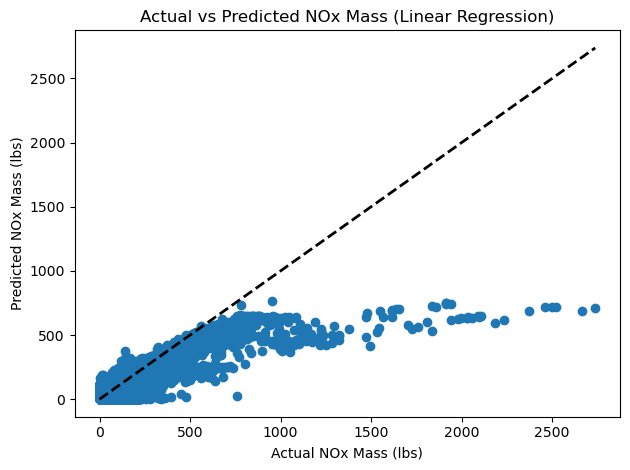

In [57]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

R^2 Score: 0.7962
Mean Squared Error (MSE): 815.8376
Root Mean Squared Error (RMSE): 28.5629
Normalized RMSE (by std): 0.4512


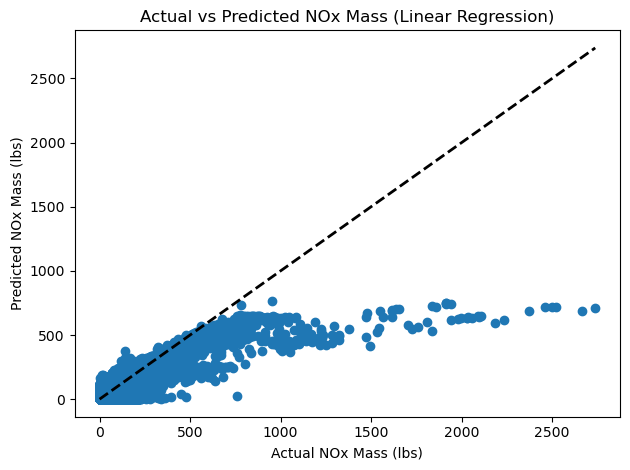

In [ ]:
# default model (no lags, no unmeasured, with temps)

# Ridge Regression

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# 
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

<h4>With Lags</h4>

In [ ]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any remaining NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9426
Mean Squared Error (MSE): 211.2194
Root Mean Squared Error (RMSE): 14.5334
Normalized RMSE (by std): 0.2393


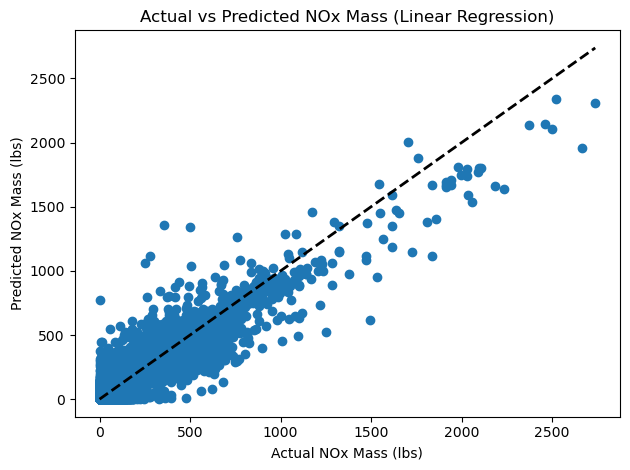

In [ ]:
# default model (with lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

<h3>Random Forest</h3>

- build RF models using sklearn default parameters without and with lags
- this version of RF handles null values inherently so we do not need to impute/remove them
- to keep training computationally feasible, we downsample the training data to 20%
- lastly, we conduct a rudimentary scenario analysis to simulate an SCR adaption across all units in 2024

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)',
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


In [ ]:
# rf struggles with large datasets, so we downsample the training data to 20%

# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_sampled = y_train.loc[y_train.index.isin(sample_indices)]

In [75]:
X_sampled.shape

(537246, 142)

<h4>No Lags</h4>

In [ ]:
# still took approx. 5 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
joblib.dump(rf_model_no_lags, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9699
Mean Squared Error (MSE): 110.7777
Root Mean Squared Error (RMSE): 10.5251
Normalized RMSE (by std): 0.1733


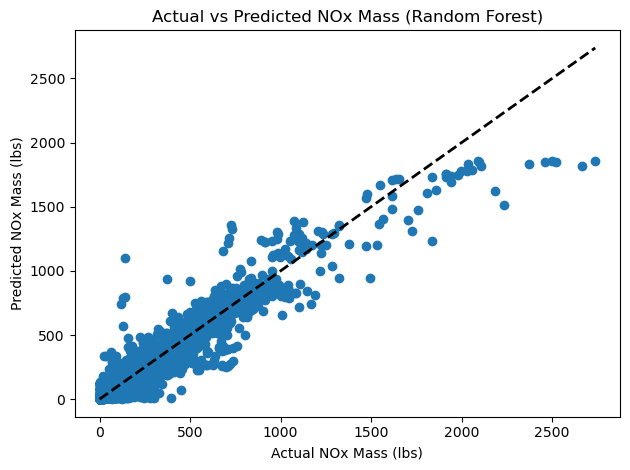

In [ ]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>With Lags</h4>

In [ ]:
# even with downsampling takes approx. 6 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

joblib.dump(rf_model_with_lags, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/xgb_default_model_ny_with_lags_with_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9846
Mean Squared Error (MSE): 56.7399
Root Mean Squared Error (RMSE): 7.5326
Normalized RMSE (by std): 0.1240


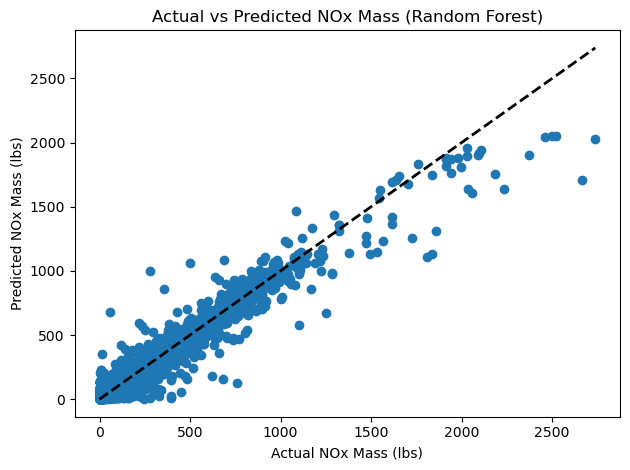

In [ ]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>Scenario Analysis</h4>

In [ ]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test

y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model underpredicts the actual NOx sum in 2024 by 1.78% which is reasonably low in relative terms
# about 193,222 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 11056084.2651
Total Actual NOx Mass (lbs): 10862861.9763
Relative Difference: 1.7787%
Total Difference: 193222.2888


In [12]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1

# model with default parameters (no short-term lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

y_pred_all_scr = rf_model_no_lags.predict(X_test_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [13]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 5.0102%
Total Difference: 553931.2855


<h3>MLP</h3>

- build an sklearn MLP model with default parameters without lags
- does not handle nulls inherently, so we remove them like for LR
- to keep training computationally feasible, we downsample the training data to 20% like for RF

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

In [25]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Summer Capacity (MW)        59.033506
Winter Capacity (MW)        59.033506
Minimum Load (MW)           59.033506
Temperature (F)              1.723858
dtype: float64

In [26]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [37]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
# features
num_features = ['Gross Load (MW)', 
              'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [38]:
# mlp struggles with large datasets, so we downsample the training data to 20%

# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>No Lags</h4>

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 16mins

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json", compress=True)

In [61]:
mlp_default_model = joblib.load("NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json")

R^2 Score: 0.9002
Mean Squared Error (MSE): 399.4277
Root Mean Squared Error (RMSE): 19.9857
Normalized RMSE (by std): 0.3157


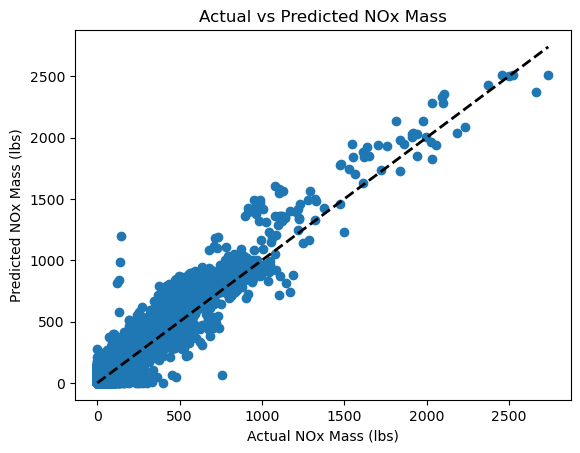

In [ ]:
y_pred = mlp_default_model.predict(X_test)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing</h5>

In [10]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [11]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [12]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Closed-coupled/Separated OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Other', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Non-catalytic Reduction',
                                  'Steam Injection', 'Water Injection',
                                  'Water Injection (Began Jul 01, 2022)', 'ARP',
                                  'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test.csv", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_train.csv", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_test.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test.csv", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_train.csv")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_test.csv")

In [13]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.csv", dtype=campd_type_dict)

In [7]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [44]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_ny_full_2024.buffer")

In [42]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_ny_full_2024.buffer")

In [8]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

<h5>Different Time Series Tests</h5>

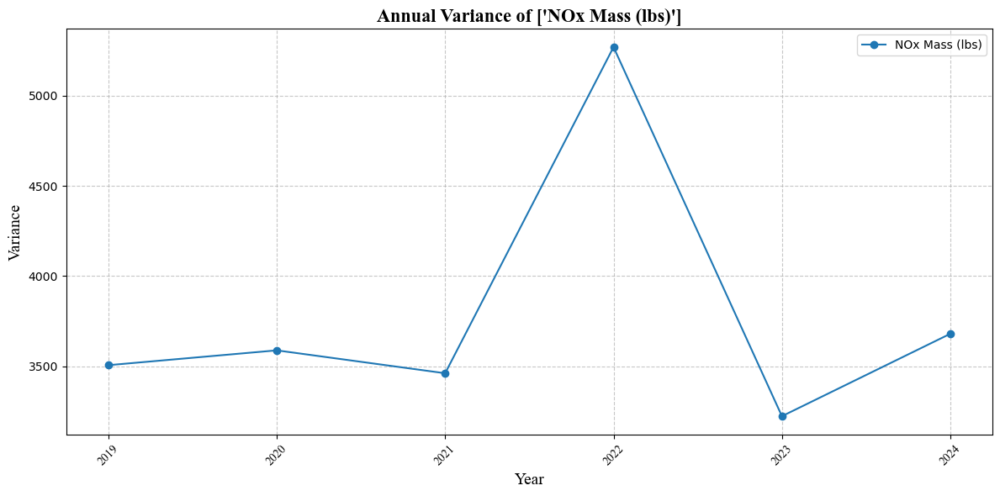

In [ ]:
# Look at yearly variance 

variables = ["NOx Mass (lbs)"]

# Set 'datetime' as index for resampling
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])
campd_df.set_index('datetime', inplace=True)
annual_variance = campd_df[variables].resample('YE').var()
annual_variance.index = annual_variance.index.year

plt.figure(figsize=(12, 6))

for var in variables:
    plt.plot(annual_variance.index, annual_variance[var], marker='o', label=var)

plt.title(f'Annual Variance of {variables}', fontsize=16, fontweight='bold', fontname='Times New Roman')
plt.xlabel('Year', fontsize=14, fontname='Times New Roman')
plt.ylabel('Variance', fontsize=14, fontname='Times New Roman')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(annual_variance.index, rotation=45, fontname='Times New Roman')
plt.tight_layout()
plt.show()


In [117]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9527, MSE: 169.9912, RMSE: 13.0381, nRMSE: 0.2177
Train: 2020, Test: 2021 | R^2: 0.9361, MSE: 221.1993, RMSE: 14.8728, nRMSE: 0.2524
Train: 2021, Test: 2022 | R^2: 0.9324, MSE: 356.3183, RMSE: 18.8764, nRMSE: 0.2600
Train: 2022, Test: 2023 | R^2: 0.9539, MSE: 148.5485, RMSE: 12.1880, nRMSE: 0.2146
Train: 2023, Test: 2024 | R^2: 0.9652, MSE: 128.0112, RMSE: 11.3142, nRMSE: 0.1863


In [30]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9527, MSE: 169.9912, RMSE: 13.0381, nRMSE: 0.2177
Train: [2019, 2020], Test: 2021 | R^2: 0.9364, MSE: 220.1571, RMSE: 14.8377, nRMSE: 0.2518
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9353, MSE: 340.9423, RMSE: 18.4646, nRMSE: 0.2543
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9604, MSE: 127.6584, RMSE: 11.2986, nRMSE: 0.1989
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9681, MSE: 117.4326, RMSE: 10.8366, nRMSE: 0.1784


In [ ]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.9498, MSE: 184.8431, RMSE: 13.5957, nRMSE: 0.2239
Train: [2019, 2020], Test: 2024 | R^2: 0.9645, MSE: 130.7925, RMSE: 11.4365, nRMSE: 0.1883
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9606, MSE: 144.8533, RMSE: 12.0355, nRMSE: 0.1982
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9622, MSE: 139.2584, RMSE: 11.8008, nRMSE: 0.1943
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9681, MSE: 117.4326, RMSE: 10.8366, nRMSE: 0.1784


<h5>Train All, Test Year 2024</h5>

<h6>"Full" Models</h6>

- uses all identified features with small variations

c:\Users\marce\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:17:19] WARNING: C:\b\abs_90_bwj_86a\croot\xgboost-split_1724073762025\work\src\context.cc:196: XGBoost is not compiled with CUDA support.
  warnings.warn(smsg, UserWarning)


R^2 Score: 0.9445
Mean Squared Error (MSE): 217.9756
Root Mean Squared Error (RMSE): 14.7640


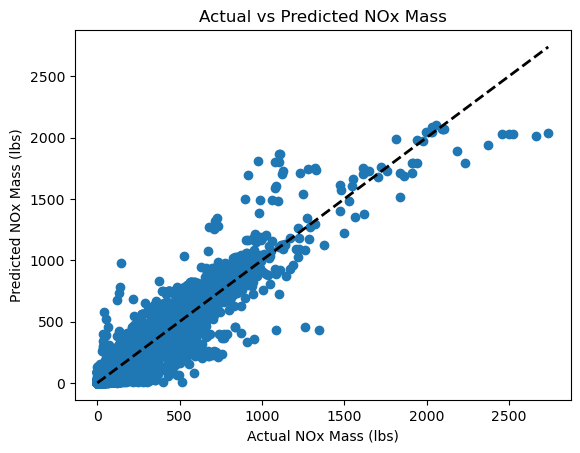

In [ ]:
# model with default parameters (no lags, with unmeasured data, no temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_with_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9641
Mean Squared Error (MSE): 132.2916
Root Mean Squared Error (RMSE): 11.5018


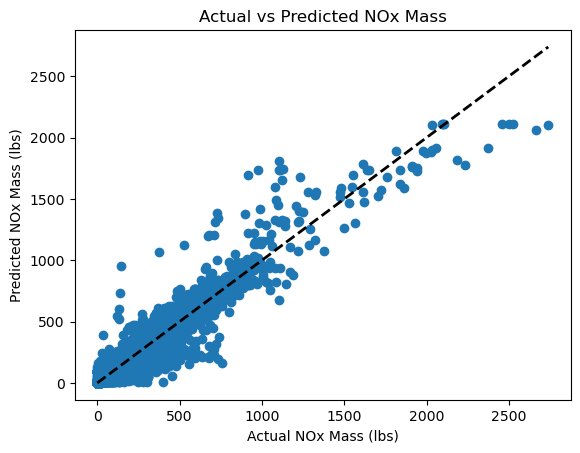

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# no cyclical cols, with categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9592
Mean Squared Error (MSE): 150.0323
Root Mean Squared Error (RMSE): 12.2488


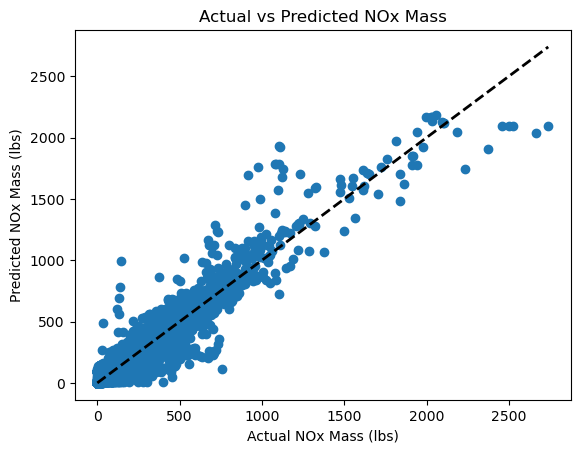

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# with cyclical cols, no categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9624
Mean Squared Error (MSE): 138.3572
Root Mean Squared Error (RMSE): 11.7625


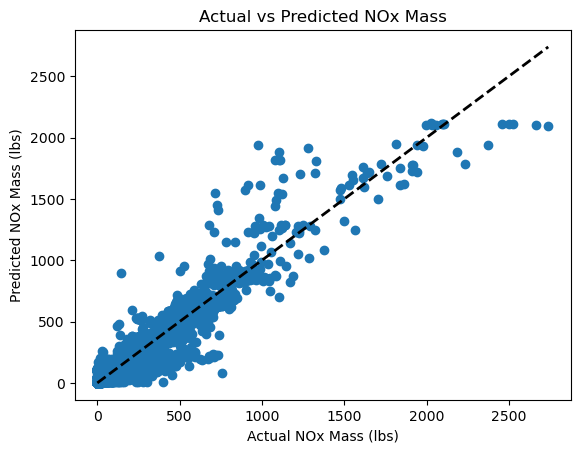

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# no cyclical cols, no categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [94]:
dtrain_no_HI = xgb.DMatrix(X_train.drop(columns="num__Heat Input (mmBtu)"), label=y_train)
dtest_no_HI = xgb.DMatrix(X_test.drop(columns="num__Heat Input (mmBtu)"), label=y_test)
dtrain_no_GL = xgb.DMatrix(X_train.drop(columns="num__Gross Load (MW)"), label=y_train)
dtest_no_GL = xgb.DMatrix(X_test.drop(columns="num__Gross Load (MW)"), label=y_test)

R^2 Score: 0.9538
Mean Squared Error (MSE): 170.1969
Root Mean Squared Error (RMSE): 13.0460
Normalized RMSE (by std): 0.2150


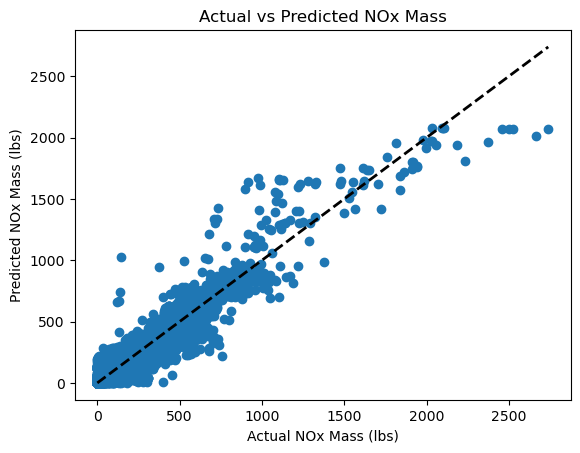

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# without heat input

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_no_HI, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest_no_HI)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_no_HI.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

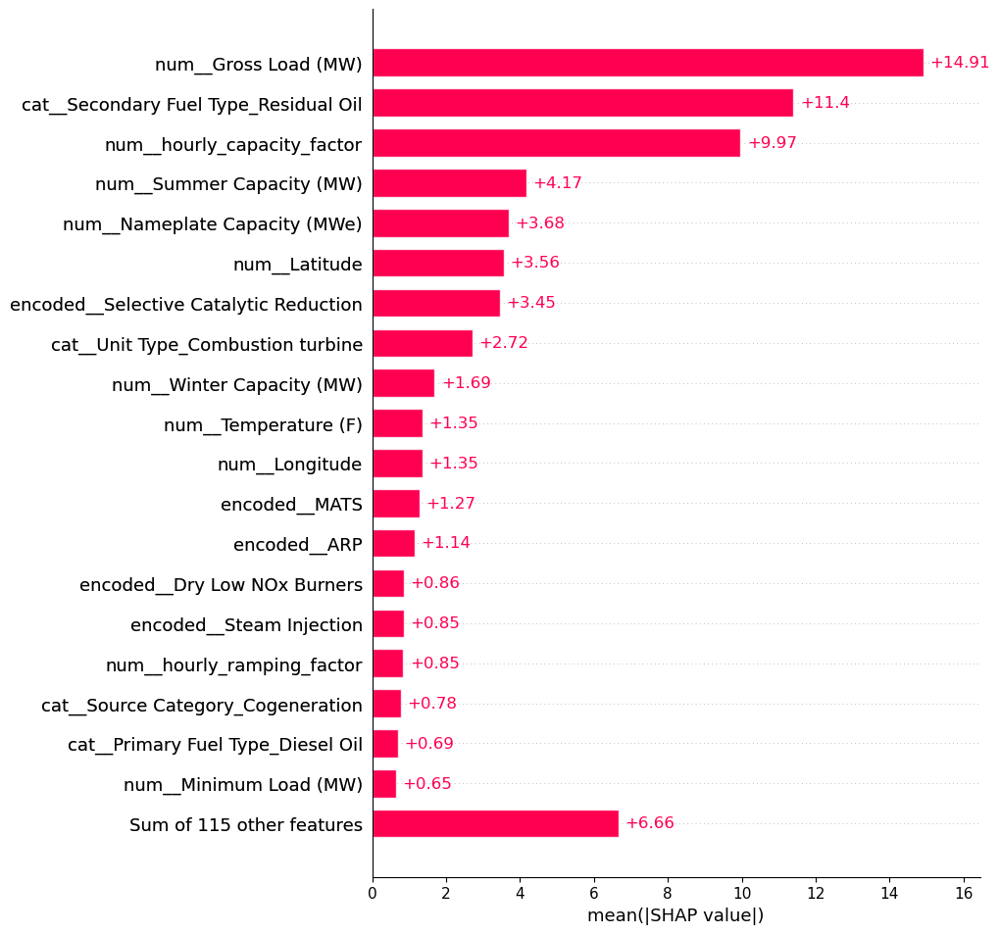

In [100]:
explainer = shap.TreeExplainer(xgb_default_model)
shap_values = explainer(X_test.drop(columns="num__Heat Input (mmBtu)"), approximate=False)
shap.plots.bar(shap_values, max_display=20)

R^2 Score: 0.9672
Mean Squared Error (MSE): 120.7082
Root Mean Squared Error (RMSE): 10.9867
Normalized RMSE (by std): 0.1811


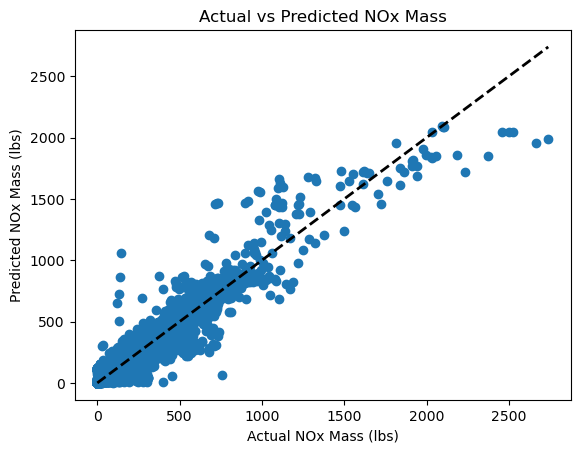

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# without gross load

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_no_GL, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest_no_GL)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_no_GL.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

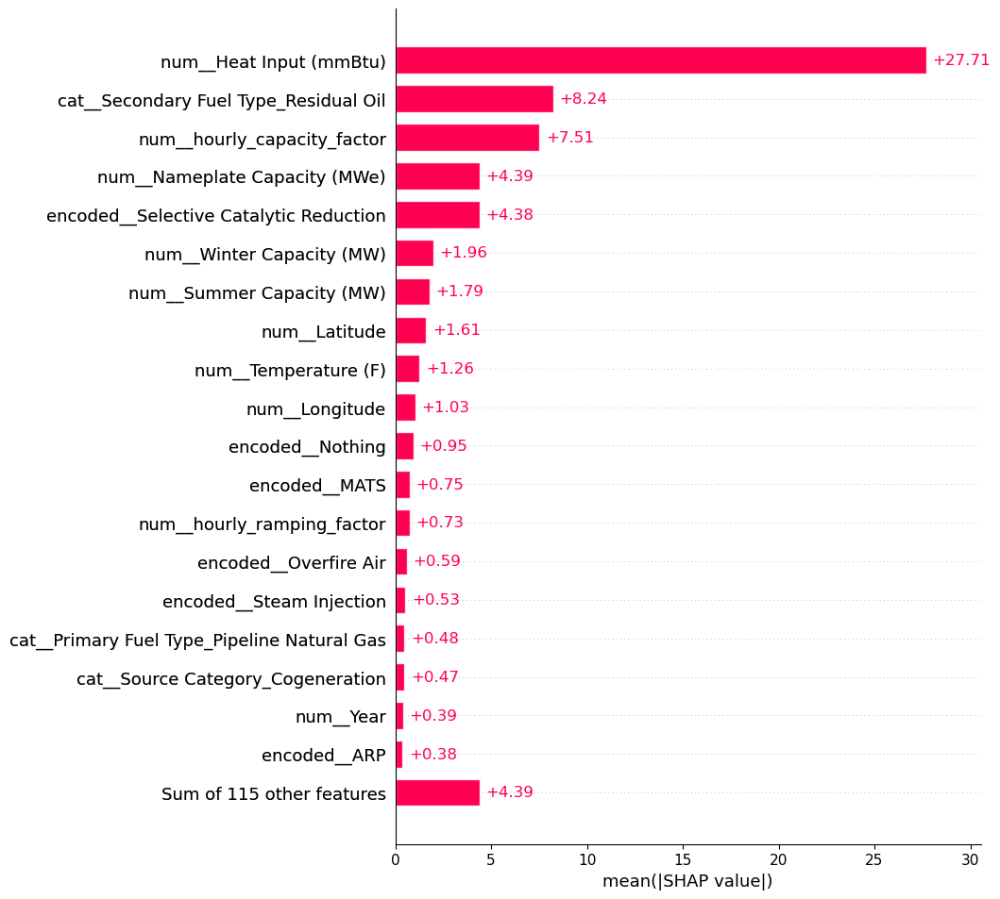

In [102]:
explainer = shap.TreeExplainer(xgb_default_model)
shap_values = explainer(X_test.drop(columns="num__Gross Load (MW)"), approximate=False)
shap.plots.bar(shap_values, max_display=20)

R^2 Score: 0.9681
Mean Squared Error (MSE): 117.4326
Root Mean Squared Error (RMSE): 10.8366
Normalized RMSE (by std): 0.1786


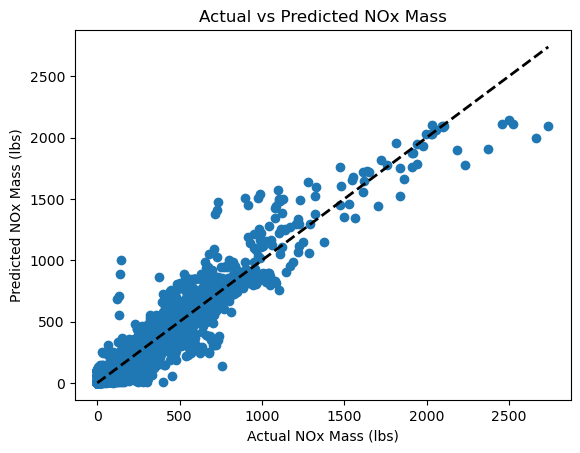

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9829
Mean Squared Error (MSE): 62.9226
Root Mean Squared Error (RMSE): 7.9324
Normalized RMSE (by std): 0.1308


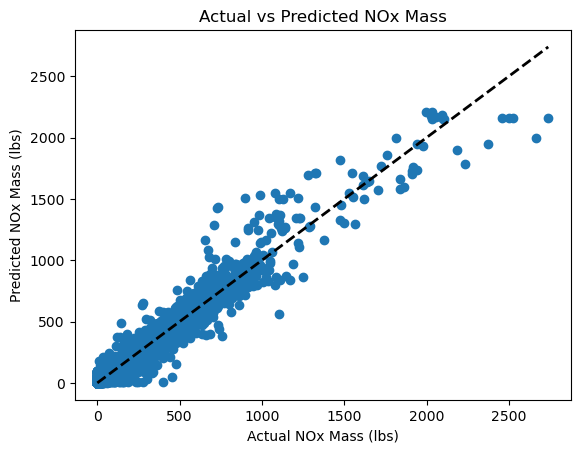

In [ ]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [48]:
mask_below_500 = y_test < 500
mask_above_500 = y_test >= 500

print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])) / np.std(y_test[mask_below_500]):.4f}")
print("")
print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])) / np.std(y_test[mask_above_500]):.4f}")


RMSE for NOx Mass below 500 lbs: 5.7844
Normalized RMSE (by std): 0.1451

RMSE for NOx Mass below 500 lbs: 83.2018
Normalized RMSE (by std): 0.3920


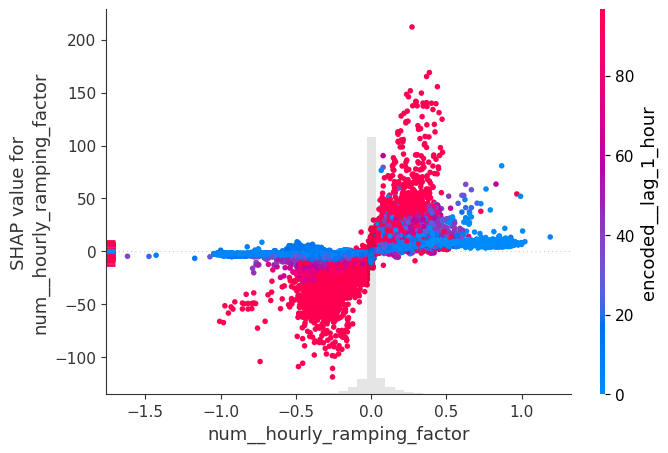

In [ ]:
shap.plots.scatter(shap_values[:, "num__hourly_ramping_factor"], color=shap_values[:, "encoded__lag_1_hour"])

# here, ramping factor becomes an immense predictor when lags do not tell the full story
# e. g. during start or shutdown, ramping interacts with lags (and HI, Gross Load etc)
# remember that we are predicting total mass and not the rate (relative to Heat Input), in that case we would expect a U-shape where start and shutdown both cause an increase in relative emissions

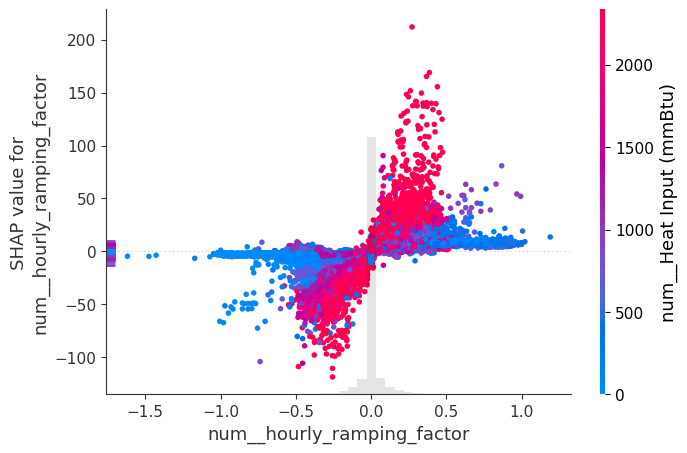

In [49]:
shap.plots.scatter(shap_values[:, "num__hourly_ramping_factor"], color=shap_values[:, "num__Heat Input (mmBtu)"])

<h6>"Reduced" Model</h6>

- removes many of the highly correlating and likely to act as proxy variables from the feature list (e. g. Gross Load, seasonal capacity, coordinates)

- the full feature list is given below

- (performance is very similar)

- we explore SHAP values quickly for comparison

In [ ]:
num_features = ['Heat Input (mmBtu)',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Year',
                'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols)

# removed: gross load, coordinates, seasonal capacity, min load, source category, NOx Phase, program code

R^2 Score: 0.9683
Mean Squared Error (MSE): 116.7366
Root Mean Squared Error (RMSE): 10.8045
Normalized RMSE (nRMSE): 0.1781


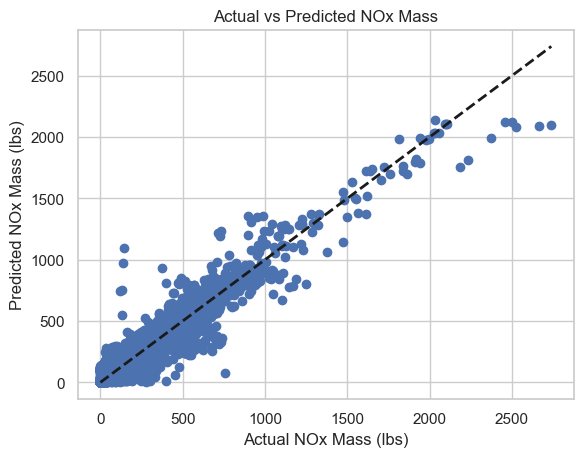

In [227]:
xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_with_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (nRMSE): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model)
shap_values_reduced_model = explainer(X_test, approximate=False)

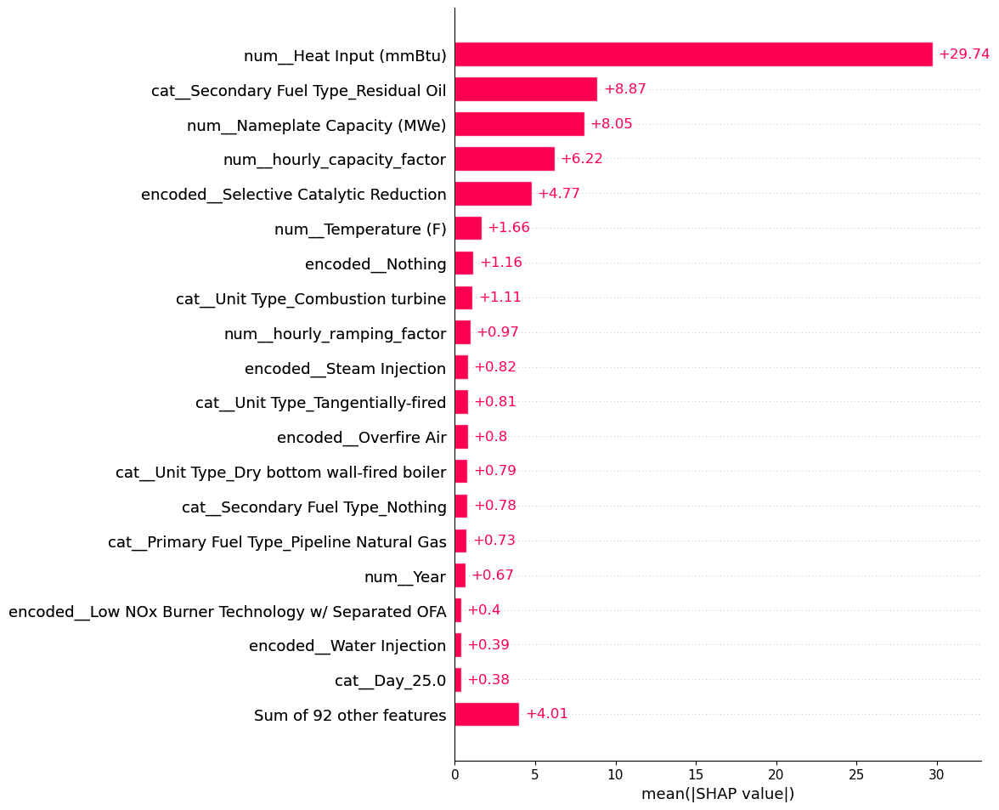

In [ ]:
shap.plots.bar(shap_values_reduced_model, max_display=20) 

# importance attributions are largely very similar to the full model

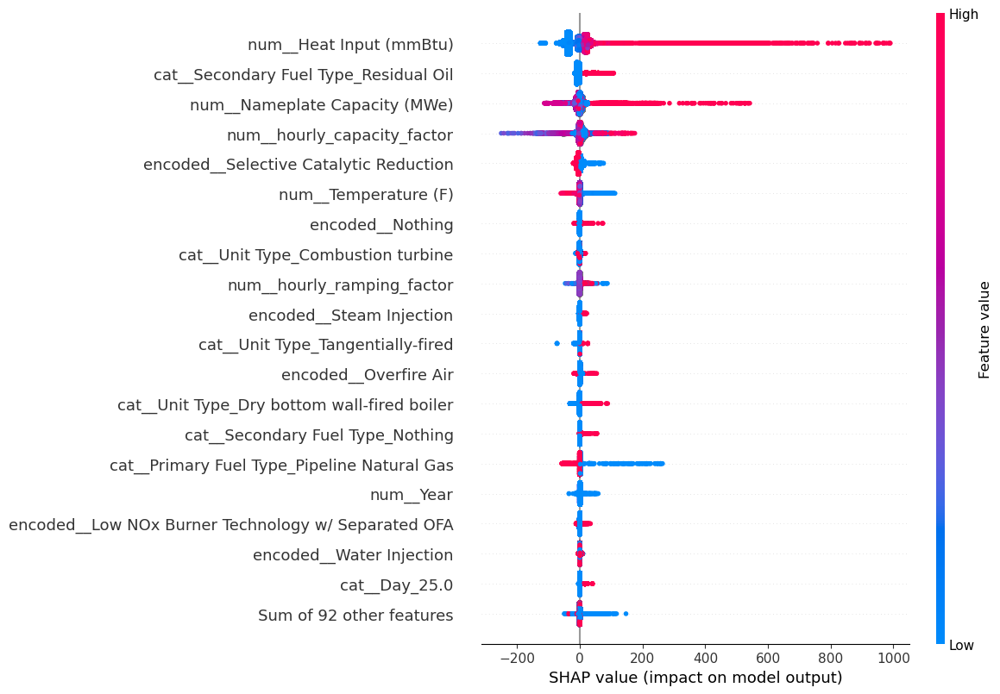

In [ ]:
shap.plots.beeswarm(shap_values_reduced_model, max_display=20)

# same here

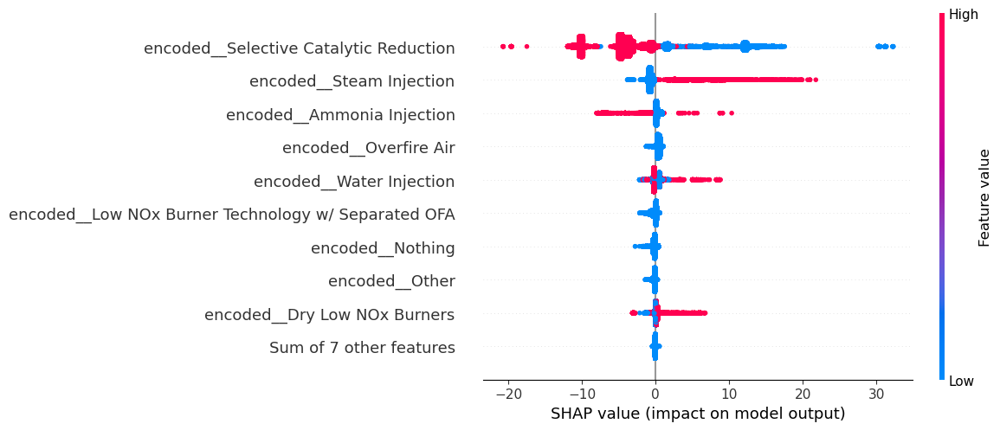

In [ ]:
# look at controls only


# create list of controls cols, formatted as in train test split
adj_control_cols = []
for control in df_control_cols:
    control = "encoded__" + control
    adj_control_cols.append(control)

# Filter using label-based indexing
comb_cycle_idx = X_test[X_test["cat__Unit Type_Combined cycle"] == 1].index
comb_turbine_idx = X_test[X_test["cat__Unit Type_Combustion turbine"] == 1].index
tangentially_fired_idx = X_test[X_test["cat__Unit Type_Tangentially-fired"] == 1].index

png_idx = X_test[X_test["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1].index
diesel_oil_idx = X_test[X_test["cat__Primary Fuel Type_Diesel Oil"] == 1].index

steam_injection_idx = X_test[X_test["encoded__Steam Injection"] == 1].index

# Convert to iloc-style positional indices
comb_cycle_iloc = X_test.index.get_indexer(comb_cycle_idx)
comb_turbine_iloc = X_test.index.get_indexer(comb_turbine_idx)
tangentially_fired_iloc = X_test.index.get_indexer(tangentially_fired_idx)

png_iloc = X_test.index.get_indexer(png_idx)
diesel_oil_iloc = X_test.index.get_indexer(diesel_oil_idx)

steam_injection_iloc = X_test.index.get_indexer(steam_injection_idx)

shap_values_comb_cyle = shap_values_reduced_model[comb_cycle_iloc]
shap_values_comb_turbine = shap_values_reduced_model[comb_turbine_iloc]
shap_values_tangentially_fired = shap_values_reduced_model[tangentially_fired_iloc]

shap_values_png = shap_values_reduced_model[png_iloc]
shap_values_diesel_oil = shap_values_reduced_model[diesel_oil_iloc]

shap_values_png_comb_cycle = shap_values_reduced_model[np.intersect1d(comb_cycle_iloc, png_iloc)]
shap_values_png_comb_turbine = shap_values_reduced_model[np.intersect1d(comb_turbine_iloc, png_iloc)]
shap_values_png_tangentially_fired = shap_values_reduced_model[np.intersect1d(tangentially_fired_iloc, png_iloc)]

# shap values of NOx control features for all combined cycle units using pipeline natural gas as primary fuel
shap.plots.beeswarm(shap_values_png_comb_cycle[:, adj_control_cols], max_display=10)

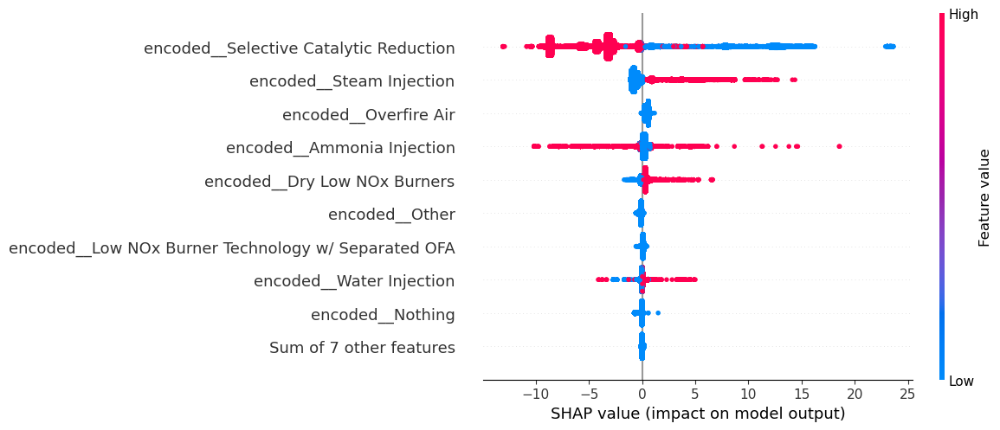

In [ ]:
# for comparison, this is what it looked like in the full model, extremely similar
shap.plots.beeswarm(shap_values_png_comb_cycle[:, adj_control_cols], max_display=10)

In [ ]:
# compare distributions among SCR and SI groups to examine differences
# that may explain the model's behavior

# Filtered data
condition = (X_test["cat__Unit Type_Combined cycle"] == 1) & \
            (X_test["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1)
X_filtered = X_test[condition].reset_index()
y_filtered = y_test.iloc[X_filtered.index.get_indexer(X_filtered.index)]

# Compare emissions for SCR vs. no SCR
group_scr_1 = y_filtered[X_filtered["encoded__Selective Catalytic Reduction"] == 1]
group_scr_0 = y_filtered[X_filtered["encoded__Selective Catalytic Reduction"] == 0]

print(f"SCR mean emissions: {group_scr_1[0].mean()}")
print(f"No SCR mean emissions: {group_scr_0[0].mean()}")

print("")

# Same for Steam Injection
group_si_1 = y_filtered[X_filtered["encoded__Steam Injection"] == 1]
group_si_0 = y_filtered[X_filtered["encoded__Steam Injection"] == 0]

print(f"Steam Injection mean emissions: {group_si_1[0].mean()}")
print(f"No Steam Injection mean emissions: {group_si_0[0].mean()}")

print("")

# Filtered data
condition = (X_test["cat__Unit Type_Combined cycle"] == 1) & \
            (X_test["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1)
X_filtered = X_test[condition].reset_index()
y_filtered = y_test.iloc[X_filtered.index.get_indexer(X_filtered.index)]

# Compare emissions for SCR vs. no SCR
group_scr_1 = X_filtered[X_filtered["encoded__Selective Catalytic Reduction"] == 1]
group_scr_0 = X_filtered[X_filtered["encoded__Selective Catalytic Reduction"] == 0]

print(f"SCR mean HI: {group_scr_1["num__Heat Input (mmBtu)"].mean()}")
print(f"No SCR mean HI: {group_scr_0["num__Heat Input (mmBtu)"].mean()}")

print("")

# Same for Steam Injection
group_si_1 = X_filtered[X_filtered["encoded__Steam Injection"] == 1]
group_si_0 = X_filtered[X_filtered["encoded__Steam Injection"] == 0]

print(f"Steam Injection mean HI: {group_si_1["num__Heat Input (mmBtu)"].mean()}")
print(f"No Steam Injection mean HI: {group_si_0["num__Heat Input (mmBtu)"].mean()}")

SCR mean emissions: 20.299034118652344
No SCR mean emissions: 20.141151428222656

Steam Injection mean emissions: 19.83196449279785
No Steam Injection mean emissions: 20.3476505279541

SCR mean HI: 1490.318930363555
No SCR mean HI: 553.1133099640417

Steam Injection mean HI: 242.7969601255493
No Steam Injection mean HI: 1514.8209849939558


In [ ]:
# possible explanation: Steam Injection is used for units that are less efficient and older 
# -> much higher emissions relative to heat input

In [ ]:
full_scr_df = campd_df[(campd_df["Year"] == 2024) & (campd_df["Unit Type"]=="Combined cycle") & (campd_df["Primary Fuel Type"]=="Pipeline Natural Gas") & (campd_df["Selective Catalytic Reduction"]==1)][["Facility Name", "Facility ID"]].drop_duplicates().sort_values(by="Facility Name")
full_steam_df = campd_df[(campd_df["Year"] == 2024) & (campd_df["Unit Type"]=="Combined cycle") & (campd_df["Primary Fuel Type"]=="Pipeline Natural Gas") & (campd_df["Steam Injection"]==1)][["Facility Name", "Facility ID"]].drop_duplicates().sort_values(by="Facility Name")

In [230]:
import plotly.graph_objects as go
import requests

data = campd_df[campd_df["Facility ID"].isin(full_steam_df["Facility ID"])][["Facility Name", "Facility ID", "Latitude", "Longitude"]].drop_duplicates()
df_valid = data.dropna(subset=["Latitude", "Longitude"])

# Compute average location
avg_lat = df_valid["Latitude"].mean()
avg_lon = df_valid["Longitude"].mean()

# Load county GeoJSON for all US counties
url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
geojson = requests.get(url).json()

# Filter counties to only New York State (FIPS codes start with '36')
ny_counties = [feature for feature in geojson['features'] if feature['id'].startswith('36')]

ny_geojson = {
    "type": "FeatureCollection",
    "features": ny_counties
}

# County IDs for locations
ny_fips_ids = [feature['id'] for feature in ny_counties]
values = [0] * len(ny_fips_ids)  # Dummy values for transparent fill

# Base map with county borders
fig = go.Figure(go.Choropleth(
    geojson=ny_geojson,
    locations=ny_fips_ids,
    z=values,
    colorscale=[[0, 'rgba(0,0,0,0)'], [1, 'rgba(0,0,0,0)']],  # transparent fill
    marker_line_color='black',  # county borders black
    marker_line_width=1,
    showscale=False,
    hoverinfo='skip',
))

# Facility markers
fig.add_trace(go.Scattergeo(
    lon=df_valid["Longitude"],
    lat=df_valid["Latitude"],
    mode='markers',
    marker=dict(size=8, color='red'),
    hovertext=df_valid[["Facility Name", "Facility ID"]],
    hoverinfo='text',
    name="Individual Facility"
))

# Average location marker
fig.add_trace(go.Scattergeo(
    lon=[avg_lon],
    lat=[avg_lat],
    mode='markers',
    marker=dict(size=12, color='blue'),
    hovertext=["Average Location"],
    hoverinfo='text',
    name="Average Location"
))

# Map settings
fig.update_geos(
    scope='usa',
    projection_type='albers usa',
    showcountries=False,
    showsubunits=False,
    fitbounds="locations",
    visible=False,
)

fig.update_layout(
    title_text="Combined Cycle + PNG + Steam Injection: Facility Locations & Average Location",
    geo=dict(bgcolor='white'),
    margin={"r":0,"t":30,"l":0,"b":0},
    showlegend=True
)


fig.show()

data = campd_df[campd_df["Facility ID"].isin(full_scr_df["Facility ID"])][["Facility Name", "Facility ID", "Latitude", "Longitude"]].drop_duplicates()
df_valid = data.dropna(subset=["Latitude", "Longitude"])

# Compute average location
avg_lat = df_valid["Latitude"].mean()
avg_lon = df_valid["Longitude"].mean()

# Load county GeoJSON for all US counties
url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
geojson = requests.get(url).json()

# Filter counties to only New York State (FIPS codes start with '36')
ny_counties = [feature for feature in geojson['features'] if feature['id'].startswith('36')]

ny_geojson = {
    "type": "FeatureCollection",
    "features": ny_counties
}

# County IDs for locations
ny_fips_ids = [feature['id'] for feature in ny_counties]
values = [0] * len(ny_fips_ids)  # Dummy values for transparent fill

# Base map with county borders
fig = go.Figure(go.Choropleth(
    geojson=ny_geojson,
    locations=ny_fips_ids,
    z=values,
    colorscale=[[0, 'rgba(0,0,0,0)'], [1, 'rgba(0,0,0,0)']],  # transparent fill
    marker_line_color='black',  # county borders black
    marker_line_width=1,
    showscale=False,
    hoverinfo='skip',
))

# Facility markers
fig.add_trace(go.Scattergeo(
    lon=df_valid["Longitude"],
    lat=df_valid["Latitude"],
    mode='markers',
    marker=dict(size=8, color='red'),
    hovertext=df_valid[["Facility Name", "Facility ID"]],
    hoverinfo='text',
    name="Individual Facility"
))

# Average location marker
fig.add_trace(go.Scattergeo(
    lon=[avg_lon],
    lat=[avg_lat],
    mode='markers',
    marker=dict(size=12, color='blue'),
    hovertext=["Average Location"],
    hoverinfo='text',
    name="Average Location",
))

# Map settings
fig.update_geos(
    scope='usa',
    projection_type='albers usa',
    showcountries=False,
    showsubunits=False,
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    title_text="Combined Cycle + PNG + SCR: Facility Locations & Average Location",
    geo=dict(bgcolor='white'),
    margin={"r":0,"t":30,"l":0,"b":0},
    showlegend=True
)


fig.show()



In [ ]:
# NY upstate facilities are generally older, see https://experience.arcgis.com/experience/bb8c905b75f84d908ab83f579498d085/page/Page
# (This page uses data from the EIA and includes calculated facility ages)

<h5>Scenario Analysis</h5>

In [56]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test


In [ ]:
y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 0.76% which is reasonably low in relative terms
# about 83,000 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 10945558.7010
Total Actual NOx Mass (lbs): 10862861.9763
Relative Difference: 0.7613%
Total Difference: 82696.7248


In [ ]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest_all_SCR = xgb.DMatrix(X_test_all_SCR, label=y_test)


In [ ]:
# model with default parameters (no short-term lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred_all_scr = xgb_default_model.predict(dtest_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [ ]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 9.3750%
Total Difference: 1026151.0000


<h5>Transferability Tests</h5>

- use NY model (2019-2023) to predict TX emissions (2024)

In [ ]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [6]:
X_test_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", dtype=campd_type_dict)
y_test_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz")

In [ ]:
# compare unit and fuel types between states

print("NY - by Unit Type and Primary Fuel Type:")
display(
    campd_df.groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)

print("TX - by Unit Type and Primary Fuel Type:")
display(
    campd_tx.groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)


NY - by Unit Type and Primary Fuel Type:


Unit Type                              Primary Fuel Type   
Circulating fluidized bed boiler       Wood                    2508647.75
Combined cycle                         Pipeline Natural Gas   21837738.00
Combined cycle (Started Feb 23, 2020)  Pipeline Natural Gas      46284.04
Combustion turbine                     Diesel Oil               414186.25
                                       Other Oil                     0.00
                                       Pipeline Natural Gas    2250384.50
Dry bottom wall-fired boiler           Coal                    1255641.12
                                       Natural Gas                   0.00
                                       Pipeline Natural Gas   10115554.00
                                       Residual Oil             678843.56
Other boiler                           Pipeline Natural Gas          0.00
Tangentially-fired                     Coal                     273577.97
                                       Natural Gas  

TX - by Unit Type and Primary Fuel Type:


Unit Type                         Primary Fuel Type   
Bubbling fluidized bed boiler     Wood                     1483502.75
Circulating fluidized bed boiler  Coal                    23344982.00
Combined cycle                    Natural Gas              1485804.38
                                  Other Gas                1664143.62
                                  Pipeline Natural Gas   175227968.00
Combustion turbine                Natural Gas               857225.62
                                  Pipeline Natural Gas    14169771.00
Dry bottom wall-fired boiler      Coal                   174859616.00
                                  Natural Gas                 3571.64
                                  Pipeline Natural Gas    83874632.00
Nothing                           Pipeline Natural Gas           0.00
Tangentially-fired                Coal                   416862464.00
                                  Pipeline Natural Gas    93228952.00
Name: NOx Mass (lbs), dtype: float3

In [ ]:
# only looking at pipeline natural gas combinations

print("NY - by Unit Type and Primary Fuel Type:")
display(
    campd_df[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas"].groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)

print("TX - by Unit Type and Primary Fuel Type:")
display(
    campd_tx[campd_tx["Primary Fuel Type"] == "Pipeline Natural Gas"].groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)


NY - by Unit Type and Primary Fuel Type:


Unit Type                              Primary Fuel Type   
Combined cycle                         Pipeline Natural Gas   21837738.00
Combined cycle (Started Feb 23, 2020)  Pipeline Natural Gas      46284.04
Combustion turbine                     Pipeline Natural Gas    2250384.50
Dry bottom wall-fired boiler           Pipeline Natural Gas   10115554.00
Other boiler                           Pipeline Natural Gas          0.00
Tangentially-fired                     Pipeline Natural Gas   25955590.00
Name: NOx Mass (lbs), dtype: float32

TX - by Unit Type and Primary Fuel Type:


Unit Type                     Primary Fuel Type   
Combined cycle                Pipeline Natural Gas   175227968.00
Combustion turbine            Pipeline Natural Gas    14169771.00
Dry bottom wall-fired boiler  Pipeline Natural Gas    83874632.00
Nothing                       Pipeline Natural Gas           0.00
Tangentially-fired            Pipeline Natural Gas    93228952.00
Name: NOx Mass (lbs), dtype: float32

In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

print("NY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("TX:")
display(campd_tx.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_tx.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


NY:


Unit Type
Tangentially-fired                      28829376.00
Combined cycle                          21837738.00
Dry bottom wall-fired boiler            12050039.00
Combustion turbine                       2664570.75
Circulating fluidized bed boiler         2508647.75
Combined cycle (Started Feb 23, 2020)      46284.04
Other boiler                                   0.00
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Pipeline Natural Gas   60205552.00
Residual Oil            3279051.00
Wood                    2508647.75
Coal                    1529219.12
Diesel Oil               414186.25
Natural Gas                   0.00
Other Oil                     0.00
Name: NOx Mass (lbs), dtype: float32

TX:


Unit Type
Tangentially-fired                 510091392.00
Dry bottom wall-fired boiler       258737808.00
Combined cycle                     178377920.00
Circulating fluidized bed boiler    23344982.00
Combustion turbine                  15026997.00
Bubbling fluidized bed boiler        1483502.75
Nothing                                    0.00
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                   615067072.00
Pipeline Natural Gas   366501312.00
Natural Gas              2346601.50
Other Gas                1664143.62
Wood                     1483502.75
Name: NOx Mass (lbs), dtype: float32

In [9]:
xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

In [ ]:
# remove lag columns
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_test_tx = X_test_tx.drop(columns=encoded_lag_cols)

In [ ]:
# columns only found in tx mostly consist of secondary fuel types

print("Columns only in tx, not ny")
print(set(X_test_tx.columns) - set(xgb_default_model_no_lags.feature_names))

Columns only in tx, not ny
{'cat__Secondary Fuel Type_Diesel Oil, Other Solid Fuel', 'cat__Secondary Fuel Type_Other Gas', 'encoded__Dry Low NOx Burners (Began Aug 03, 2022)', 'encoded__Dry Low NOx Burners (Began Jul 01, 2024)', 'cat__Secondary Fuel Type_Diesel Oil, Residual Oil', 'encoded__TXSO2', 'encoded__Steam Injection (Retired Jun 30, 2024)', 'cat__Secondary Fuel Type_Process Gas', 'cat__Unit Type_Nothing', 'encoded__Steam Injection (Retired Aug 02, 2022)', 'cat__Unit Type_Bubbling fluidized bed boiler', 'cat__Secondary Fuel Type_Diesel Oil, Other Oil', 'cat__Primary Fuel Type_Other Gas', 'cat__Secondary Fuel Type_Other Gas, Process Gas'}


In [ ]:
# adjust columns such that tx has the same features as ny, if a (categorical) column exists in ny, but not tx we set it 0 for all rows
# if it only exists in tx, we drop it

ny_features = xgb_default_model_no_lags.feature_names
tx_features = X_test_tx.columns.tolist()

X_test_tx_adjusted = X_test_tx.copy()

# Features to add (with 0s)
features_to_add = list(set(ny_features) - set(tx_features)) # features in ny, but not tx
for feature in features_to_add:
    X_test_tx_adjusted[feature] = 0

# Features to drop
features_to_drop = list(set(tx_features) - set(ny_features)) # features in tx, but not ny
X_test_tx_adjusted.drop(columns=features_to_drop, inplace=True)

# Reorder the columns to match ny_features
X_test_tx_adjusted = X_test_tx_adjusted[ny_features]

In [17]:
shared_unit_types = list(set(campd_tx["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
print(shared_unit_types)

['Circulating fluidized bed boiler', 'Dry bottom wall-fired boiler', 'Combined cycle', 'Tangentially-fired', 'Combustion turbine']


In [101]:
# filter tx data to only include units part of ny training data
X_test_tx_adjusted_filtered = X_test_tx_adjusted[
    (X_test_tx_adjusted["cat__Unit Type_Tangentially-fired"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Combustion turbine"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Dry bottom wall-fired boiler"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Circulating fluidized bed boiler"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Combined cycle"] == 1)
]

y_test_tx_filtered = y_test_tx[X_test_tx_adjusted_filtered.index]

In [37]:
shared_fuel_types = list(set(campd_tx["Primary Fuel Type"]).intersection(set(campd_df["Primary Fuel Type"].unique())))
print(shared_fuel_types)

['Pipeline Natural Gas', 'Coal', 'Wood', 'Natural Gas']


In [106]:
# Filter TX data to only include pipeline natural gas

X_test_tx_adjusted_filtered = X_test_tx_adjusted_filtered[
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Coal"] == 0) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Wood"] == 0) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Natural Gas"] == 0)
]

y_test_tx_filtered = y_test_tx_filtered[X_test_tx_adjusted_filtered.index]

In [ ]:
X_test_tx_adjusted.shape[0] - X_test_tx_adjusted_filtered.shape[0]

# removed no of rows for filtered test set

238443

In [85]:
dtest_tx_adjusted = xgb.DMatrix(X_test_tx_adjusted, label=y_test_tx)
dtest_tx_adjusted_filtered = xgb.DMatrix(X_test_tx_adjusted_filtered, label=y_test_tx_filtered)

R^2 Score: 0.1330
Mean Squared Error (MSE): 36557.9648
Root Mean Squared Error (RMSE): 191.2014
Normalized RMSE (by std): 0.9311


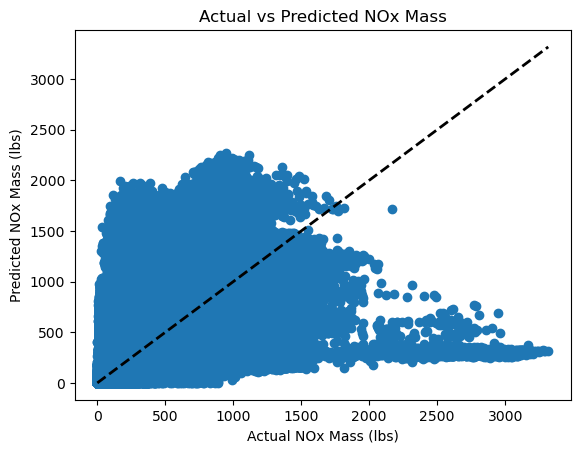

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# prediction tx data includes unit types that are unseen for the ny model

y_pred = xgb_default_model_no_lags.predict(dtest_tx_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_tx_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

# very bad performance

In [141]:
campd_tx["NOx Mass (lbs)"].describe()

count   9758706.00
mean        101.15
std         208.90
min           0.00
25%          10.80
50%          25.10
75%          61.70
max        8746.60
Name: NOx Mass (lbs), dtype: float64

In [140]:
campd_df["NOx Mass (lbs)"].describe()

count   3197828.00
mean         21.24
std          60.45
min           0.00
25%           0.00
50%           7.60
75%          14.80
max        2738.50
Name: NOx Mass (lbs), dtype: float64

R^2 Score: 0.0787
Mean Squared Error (MSE): 15897.1318
Root Mean Squared Error (RMSE): 126.0838
Normalized RMSE (by std): 0.9599


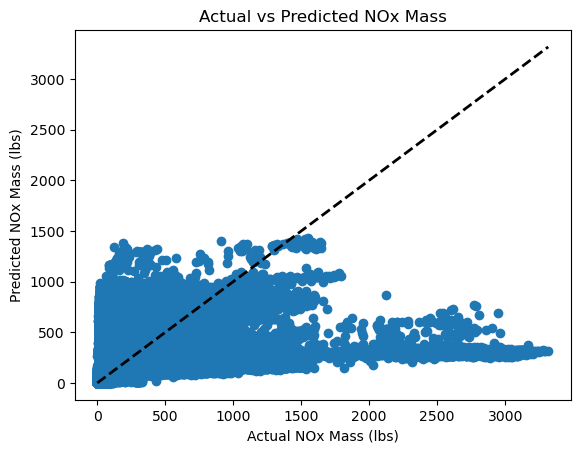

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# predict only on TX pipeline natural gas data

y_pred = xgb_default_model_no_lags.predict(dtest_tx_adjusted_filtered)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_tx_adjusted_filtered.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

# performance is even worse

In [ ]:
# Filter original dataset and add predictions to look at how the NY model performs over time

campd_tx_filtered = campd_tx[(campd_tx["Unit Type"].isin(["Tangentially-fired", "Combustion turbine", "Dry bottom wall-fired boiler", 
                                      "Circulating fluidized bed boiler", "Combined cycle"]) 
                                    ) & (campd_tx["Primary Fuel Type"] == "Pipeline Natural Gas") & (campd_tx["Year"] == 2024)]

In [126]:
campd_tx_filtered = campd_tx_filtered.reset_index(drop=True)
y_test_tx_filtered = y_test_tx_filtered.reset_index(drop=True)

campd_tx_filtered["Y_test"] = y_test_tx_filtered
campd_tx_filtered["Y_pred"] = y_pred

In [128]:
campd_tx_filtered[["datetime","NOx Mass (lbs)", "Y_test", "Y_pred"]]

,datetime,NOx Mass (lbs),Y_test,Y_pred
0,2024-01-01 00:00:00,0.00,0.00,0.00
1,2024-01-01 00:00:00,21.30,21.30,22.28
2,2024-01-01 00:00:00,159.60,159.60,58.89
3,2024-01-01 00:00:00,122.10,122.10,57.88
4,2024-01-01 00:00:00,98.30,98.30,54.40
...,...,...,...,...
1481732,2024-12-31 23:00:00,21.10,21.10,866.90
1481733,2024-12-31 23:00:00,0.00,0.00,0.00
1481734,2024-12-31 23:00:00,0.00,0.00,0.00
1481735,2024-12-31 23:00:00,0.00,0.00,0.00


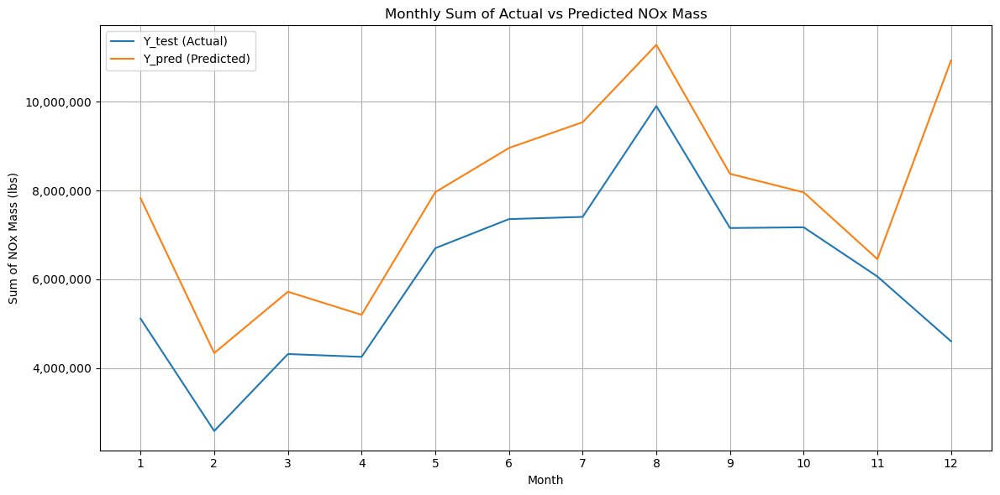

In [ ]:
campd_tx_filtered['datetime'] = pd.to_datetime(campd_tx_filtered['datetime'])

monthly_sum = campd_tx_filtered.groupby(campd_tx_filtered['datetime'].dt.month)[
    ["NOx Mass (lbs)", "Y_test", "Y_pred"]
].sum().reset_index()

plt.figure(figsize=(12,6))

plt.plot(monthly_sum['datetime'], monthly_sum['Y_test'], label='Y_test (Actual)')
plt.plot(monthly_sum['datetime'], monthly_sum['Y_pred'], label='Y_pred (Predicted)')

plt.xlabel('Month')
plt.xticks(range(1, 13))
plt.ylabel('Sum of NOx Mass (lbs)')
plt.title('Monthly Sum of Actual vs Predicted NOx Mass')

plt.legend()
plt.grid(True)

# Format y-axis ticks with commas
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()

# the model consistently underestimates, though trends are largely similar except for the end of the year

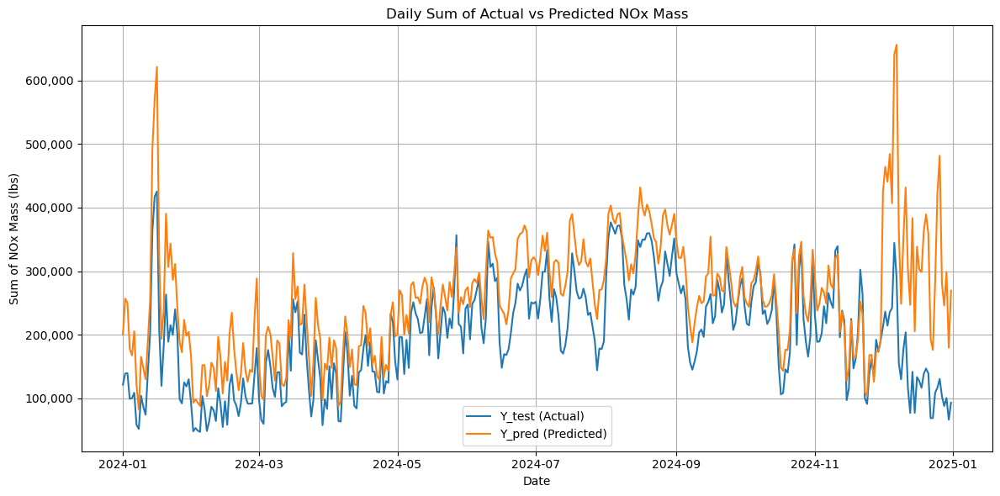

In [ ]:
daily_sum = campd_tx_filtered.groupby(campd_tx_filtered['datetime'].dt.date)[
    ["NOx Mass (lbs)", "Y_test", "Y_pred"]
].sum().reset_index()


plt.figure(figsize=(12,6))

plt.plot(daily_sum['datetime'], daily_sum['Y_test'], label='Y_test (Actual)')
plt.plot(daily_sum['datetime'], daily_sum['Y_pred'], label='Y_pred (Predicted)')

plt.xlabel('Date')
plt.ylabel('Sum of NOx Mass (lbs)')
plt.title('Daily Sum of Actual vs Predicted NOx Mass')
plt.legend()
plt.grid(True)

# Format y-axis ticks with commas
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()


<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models

mlp_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json")

rf_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_with_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

<h3>RF (model-specific)</h3>

- Mean Decrease in Impurity (MDI) for RF without and with lags

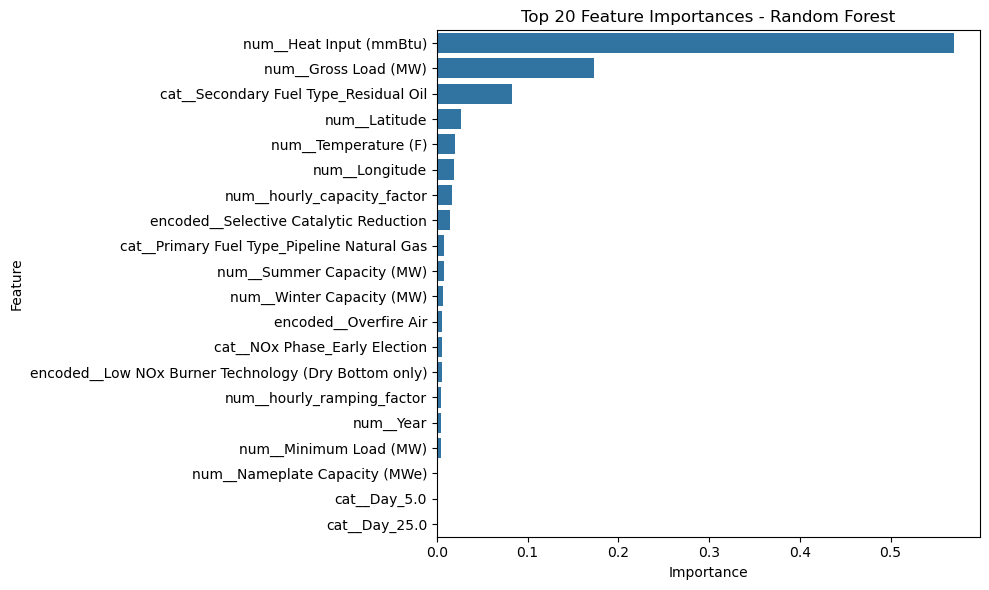

In [ ]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


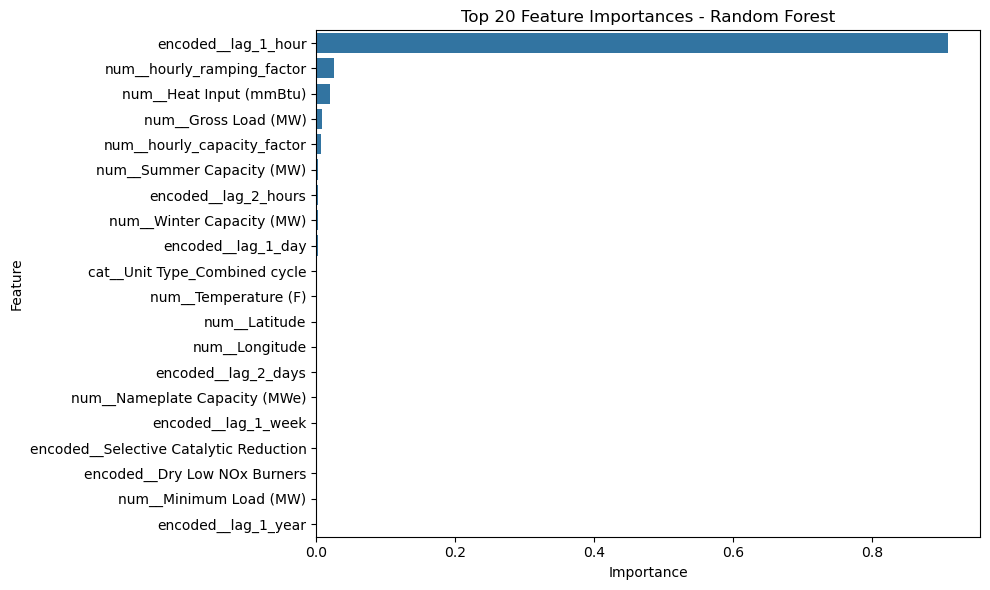

In [ ]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

- Weight, gain, and cover for XGB with and without lags

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

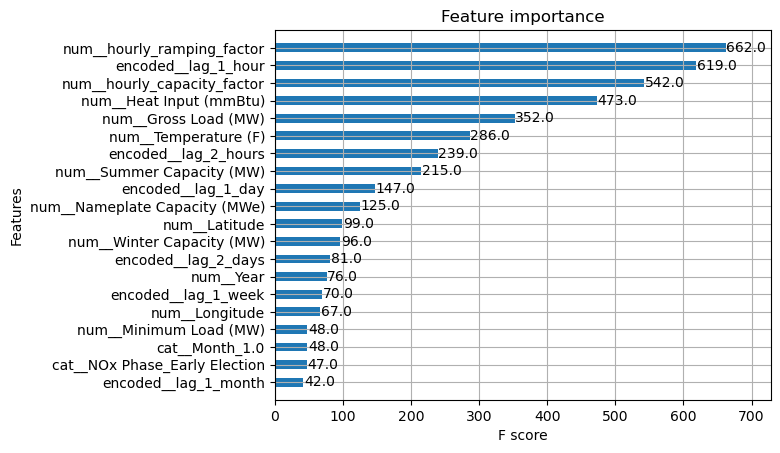

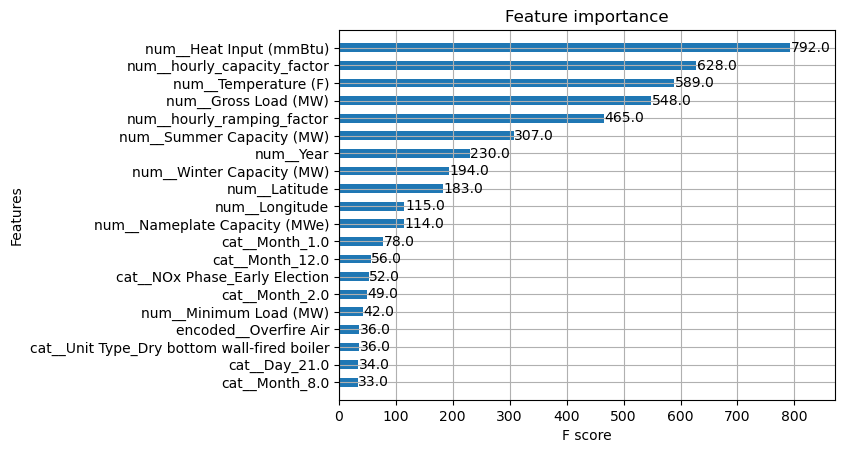

In [70]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

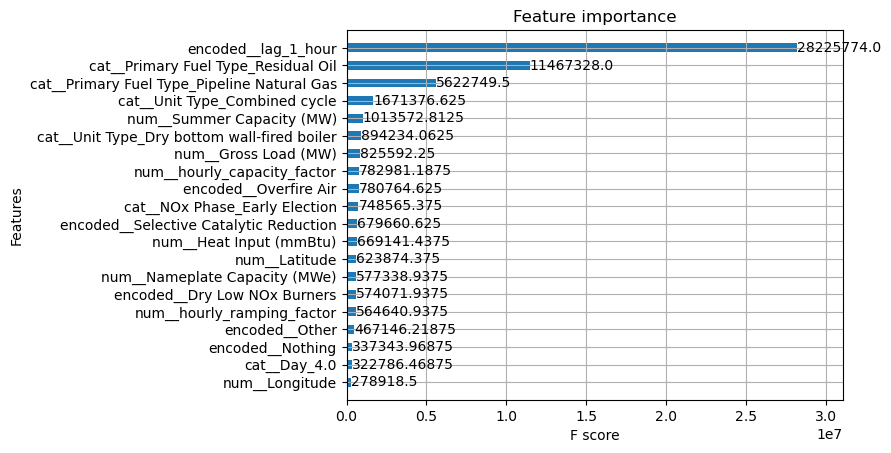

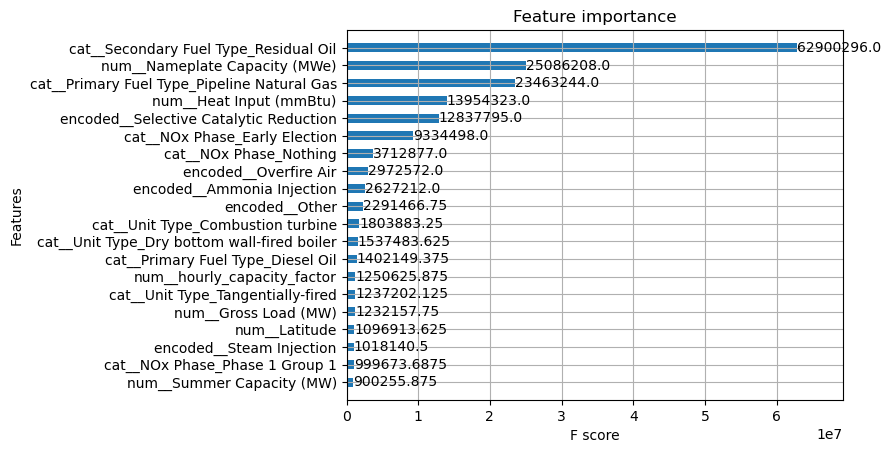

In [71]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

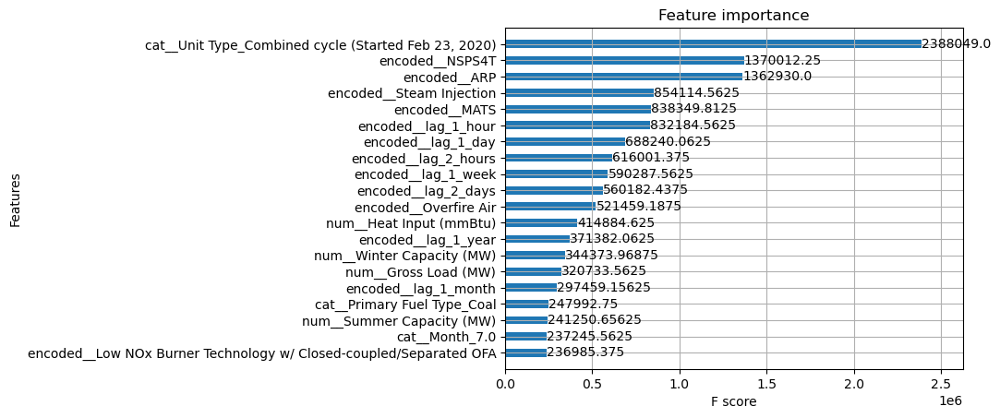

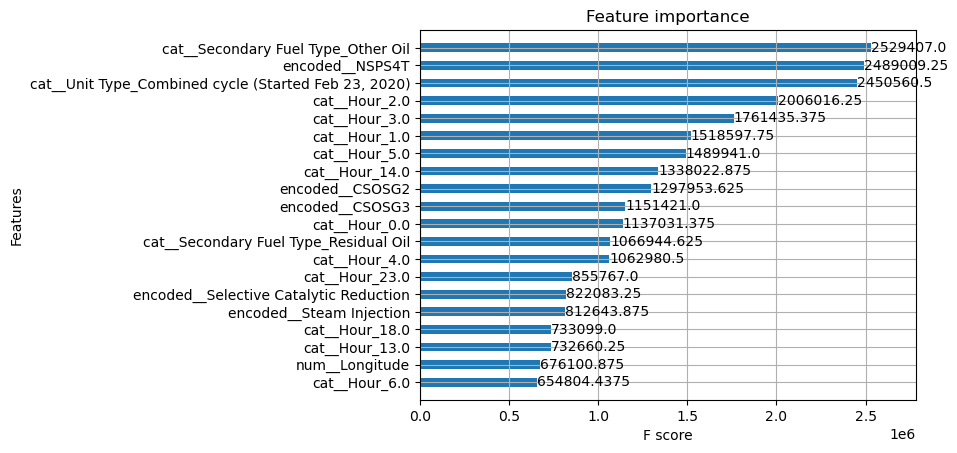

In [72]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

- exploration of PDP and ICE plots for Residual Oil and Temperature

In [72]:
xgb_default_model_no_lags_regressor = XGBRegressor()
xgb_default_model_no_lags_regressor._Booster = xgb_default_model_no_lags

In [69]:
print(campd_df[campd_df["Secondary Fuel Type"] == "Residual Oil"].shape)
print(campd_df[campd_df["Secondary Fuel Type"] != "Residual Oil"].shape)

(366086, 95)
(2831742, 95)


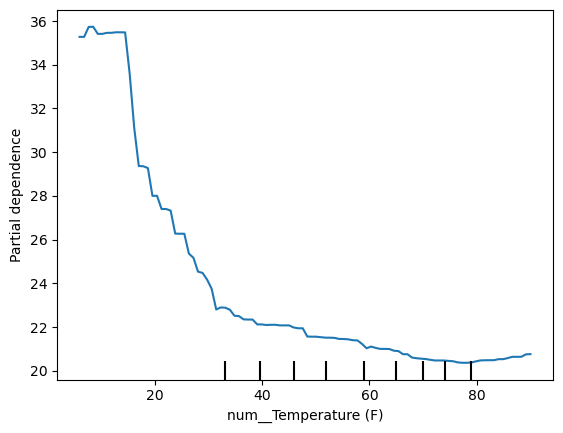

In [ ]:
# conventional pdp using sklearn
PartialDependenceDisplay.from_estimator(xgb_default_model_no_lags_regressor, X_test, ["num__Temperature (F)"], kind="average", n_jobs=-1)

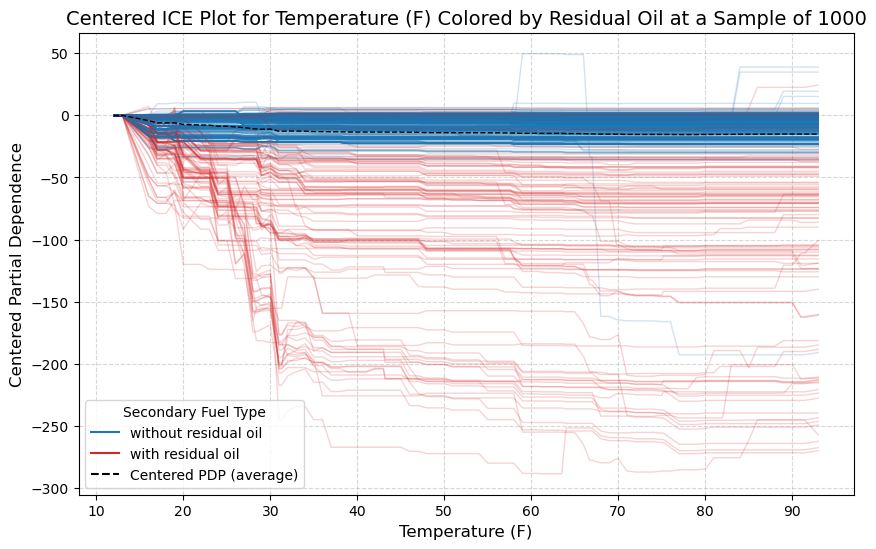

In [ ]:

X_sampled = X_test.sample(1000, random_state=42)

# Compute partial dependence 
pdp_lines = partial_dependence(
    xgb_default_model_no_lags_regressor,
    X_sampled,
    ["num__Temperature (F)"],
    kind="both"
)

# Define the color feature and colors for ICE curves
color_feature = "cat__Secondary Fuel Type_Residual Oil"
colors = ["tab:blue", "tab:red"]

plt.figure(figsize=(10, 6))

# Plot centered ICE curves for each instance
for i in range(0, X_sampled.shape[0]):
    # Ensure binary values for the color feature
    color = colors[int(round(X_sampled[color_feature].values[i]))]
    
    # Center the ICE curve by subtracting the first prediction value
    centered_curve = pdp_lines["individual"][0][i] - pdp_lines["individual"][0][i][0]
    
    plt.plot(
        pdp_lines["grid_values"][0],  # x-axis: temperature grid
        centered_curve,  # y-axis: centered prediction curve
        linewidth=1,
        color=color,
        alpha=0.2  # Add transparency for overlapping curves
    )

# Overlay the PDP (average of ICE curves), also centered
pdp = pdp_lines["average"][0]
centered_pdp = pdp - pdp[0]  # Center the PDP by subtracting the first value
plt.plot(
    pdp_lines["grid_values"][0],
    centered_pdp,
    linewidth=1,
    color="black",
    linestyle="--",
    label="Centered PDP (average)"
)

plt.ylabel("Centered Partial Dependence", size=12)
plt.xlabel("Temperature (F)", size=12)
plt.title("Centered ICE Plot for Temperature (F) Colored by Residual Oil at a Sample of 1000", size=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(
    handles=[
        plt.Line2D([0], [0], color=colors[0], label="without residual oil"),
        plt.Line2D([0], [0], color=colors[1], label="with residual oil"),
        plt.Line2D([0], [0], color="black", linestyle="--", label="Centered PDP (average)")
    ],
    title="Secondary Fuel Type"
)
plt.show()

In [ ]:
print(campd_df[campd_df["Secondary Fuel Type"] == "Residual Oil"]["NOx Mass (lbs)"].mean())
print(campd_df[campd_df["Secondary Fuel Type"] != "Residual Oil"]["NOx Mass (lbs)"].mean())

100.8475
10.953611


In [ ]:
print(campd_df[campd_df["Secondary Fuel Type"] == "Residual Oil"]["Heat Input (mmBtu)"].mean())
print(campd_df[campd_df["Secondary Fuel Type"] != "Residual Oil"]["Heat Input (mmBtu)"].mean())

1239.0649012527113
755.0141330446061


In [ ]:
campd_df.groupby(by="Secondary Fuel Type")["NOx Mass (lbs)"].mean()

Secondary Fuel Type
Diesel Oil                                              10.722231
Natural Gas, Wood                                        0.000000
Nothing                                                  8.161778
Other Oil                                                2.616461
Other Solid Fuel, Petroleum Coke, Tire Derived Fuel     26.810099
Pipeline Natural Gas                                    21.893093
Residual Oil                                           100.847504
Wood                                                    13.274329
Name: NOx Mass (lbs), dtype: float32

<h3>Permutation Importance</h3>

- compute and display permutation importance without lags both without and with feature grouping to combat multicollinearity

In [5]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

<h4>Ungrouped</h4>

In [17]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
97,num__Heat Input (mmBtu),11724.908880,23.573007
96,num__Gross Load (MW),2396.952011,1.034504
101,num__hourly_capacity_factor,1829.990463,3.513026
100,num__Nameplate Capacity (MWe),1432.571070,11.385595
94,cat__Secondary Fuel Type_Residual Oil,965.793727,3.417246
...,...,...,...
7,cat__Month_8.0,-0.471741,0.082753
112,encoded__Low NOx Burner Technology w/ Closed-c...,-0.514760,0.033586
62,cat__Day_27.0,-1.122091,0.063228
57,cat__Day_22.0,-1.159053,0.085806


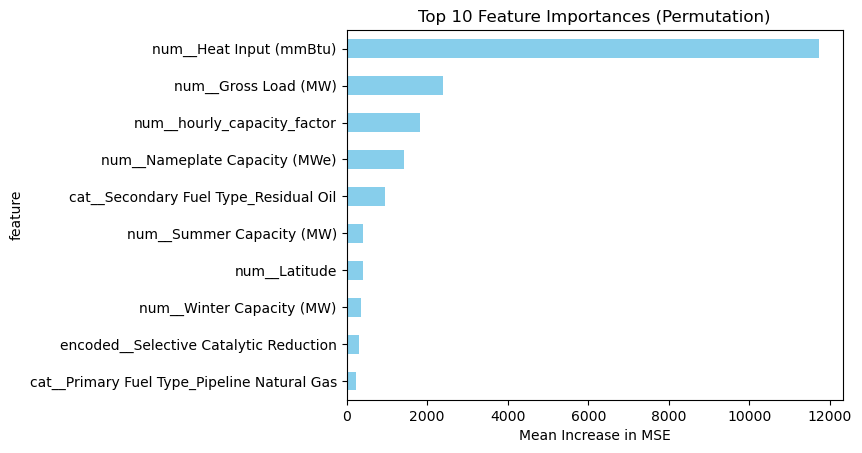

In [18]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h4>Grouped</h4>

- group features with over 80% correlation (Spearman) and retrain i. e. select only one feature per group


In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed.csv", dtype=campd_type_dict)
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")

In [ ]:
# group features with over 80% correlation (Spearman) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9605
Mean Squared Error (MSE): 145.2922
Root Mean Squared Error (RMSE): 12.0537


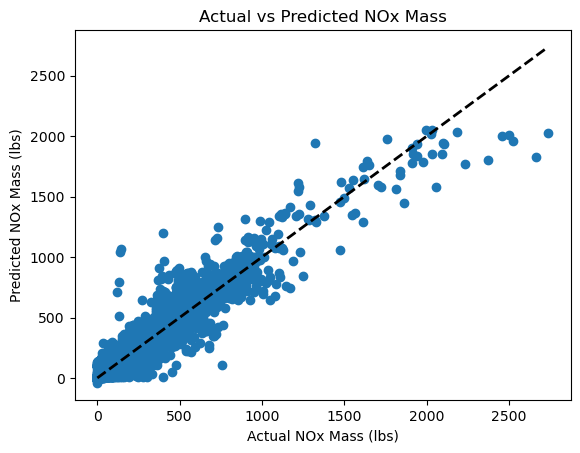

In [ ]:
xgb_default_model_no_corr = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model_no_corr.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [25]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_corr

In [26]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error')

In [27]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


                                               feature  importance_mean  \
96                             num__Heat Input (mmBtu)     10104.394613   
99                       num__Nameplate Capacity (MWe)      1933.974365   
94               cat__Secondary Fuel Type_Residual Oil      1267.873454   
101                             num__Minimum Load (MW)       502.353231   
115             encoded__Selective Catalytic Reduction       373.037577   
..                                                 ...              ...   
50                                       cat__Day_15.0        -0.500361   
108  encoded__Low NOx Burner Technology w/ Closed-c...        -0.581757   
57                                       cat__Day_22.0        -0.656265   
5                                       cat__Month_6.0        -0.741221   
11                                     cat__Month_12.0        -3.522715   

     importance_std  
96        86.214419  
99        10.873814  
94         4.096822  
101        

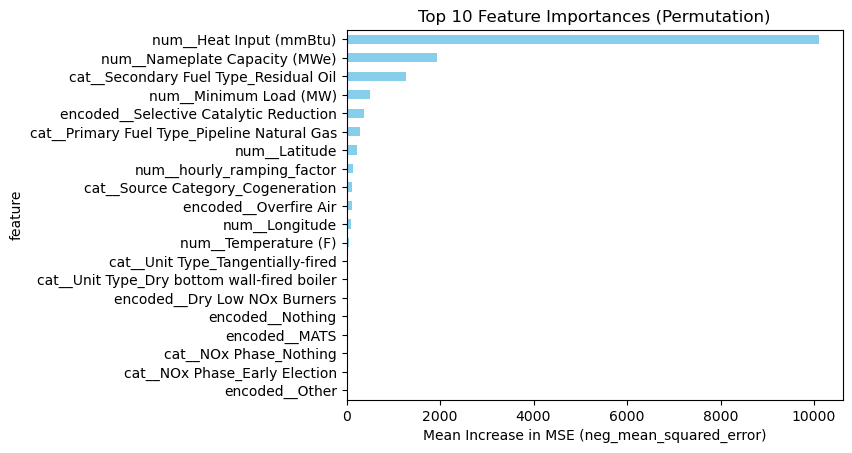

In [28]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

- compute SHAP values for each model type

<h4>LR</h4>

- compute for both LR and Ridge Regression to show the effect of regularization on interpretability

In [ ]:
# interventional algorithm stays "true to the model" -> shows how the model actually uses features without respect for correlation
# correlation_dependent stays "true to the data" -> distributes attributions between correlated features
# https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html

In [55]:
# lr model with ridge regularization (no lags)
explainer = shap.LinearExplainer(lr_model, shap.sample(X_train, random_state=42))
shap_values = explainer(X_test)

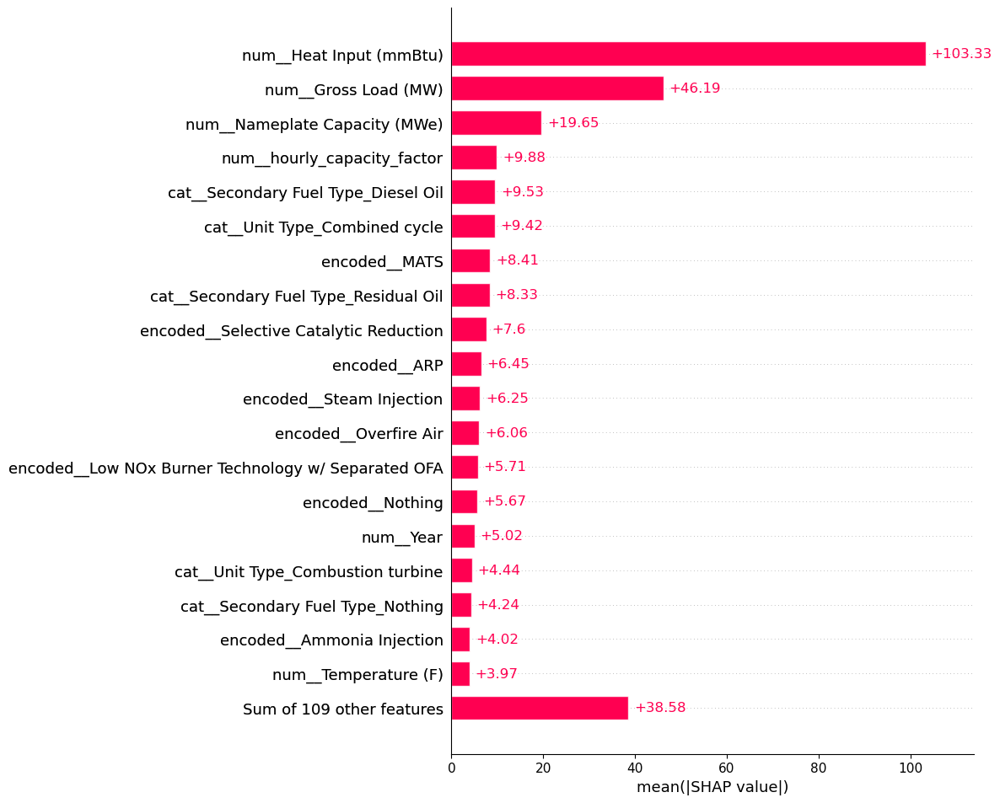

In [ ]:
shap.plots.bar(shap_values, max_display=20)

# note that we removed some null rows and columns to be consistent with model assumptions meaning that there are only 128 features

In [59]:
# normal LR without ridge regression
explainer = shap.LinearExplainer(lr_model, shap.sample(X_train, random_state=42))
shap_values = explainer(X_test)

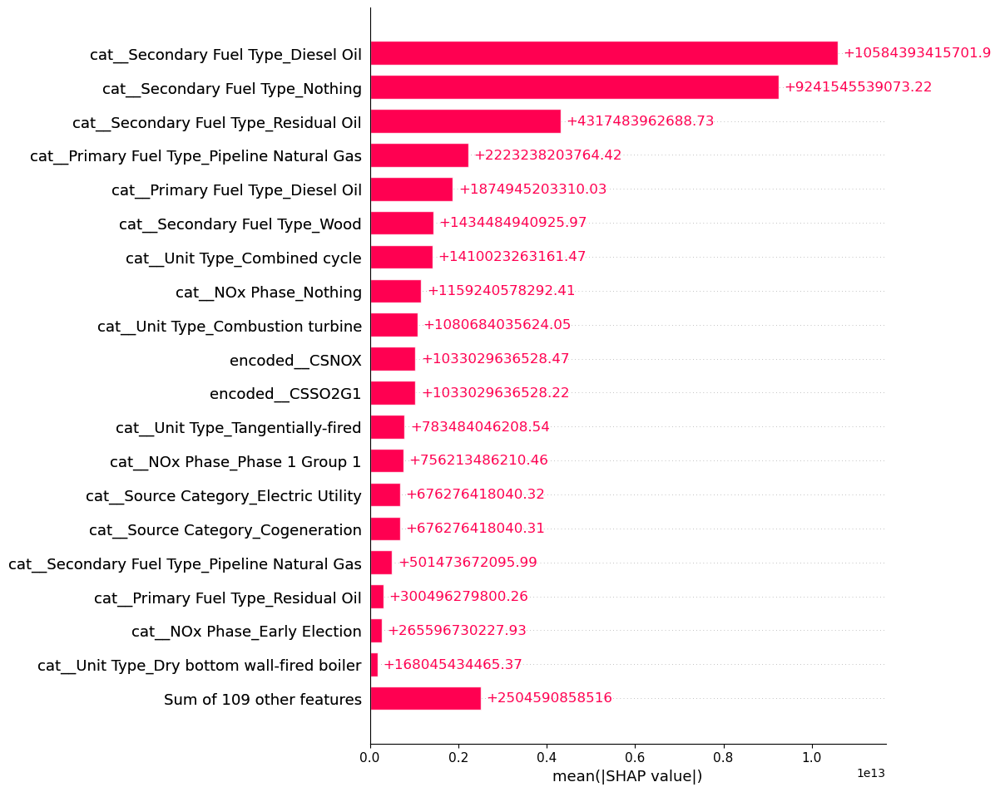

In [60]:
shap.plots.bar(shap_values, max_display=20)

# coefficients are extremely large and nonsensical

<h4>MLP</h4>

In [ ]:
# we cannot use deepexplainer since it is only compatible with tensorflow and keras (we are using sklearn)

# using KernelExplainer would take extremely long
# explainer = shap.KernelExplainer(mlp_default_model_no_lags.predict, shap.sample(X_train, random_state=42))

# so instead we use the permutation algorithm which is similar to kernelshap, but uses permutation for approximation
explainer = shap.Explainer(mlp_default_model_no_lags.predict, shap.sample(X_train, random_state=42), algorithm="permutation")
shap_values = explainer(X_test.sample(20000, random_state=42))

# this still took 15mins


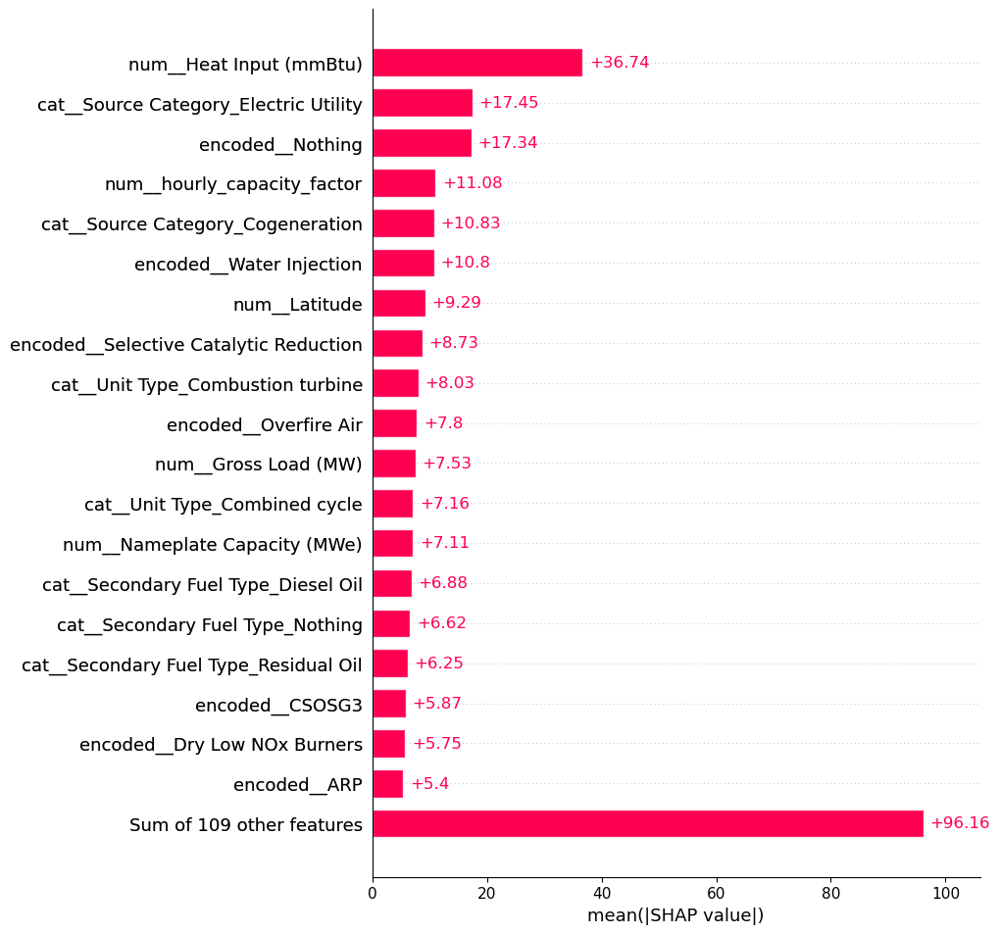

In [ ]:
shap.plots.bar(shap_values, max_display=20)

# note that we removed some null rows and columns to be consistent with model assumptions meaning that there are only 128 features

<h4>RF</h4>

- global values as well as a brief exploration of scatter plots for temperature and SCR (allows comparison to XGB)

In [6]:
explainer = shap.TreeExplainer(rf_default_model_no_lags)

In [ ]:
# takes over 15 mins without approximation
shap_values = explainer(X_test, approximate=True)

In [8]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

In [4]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

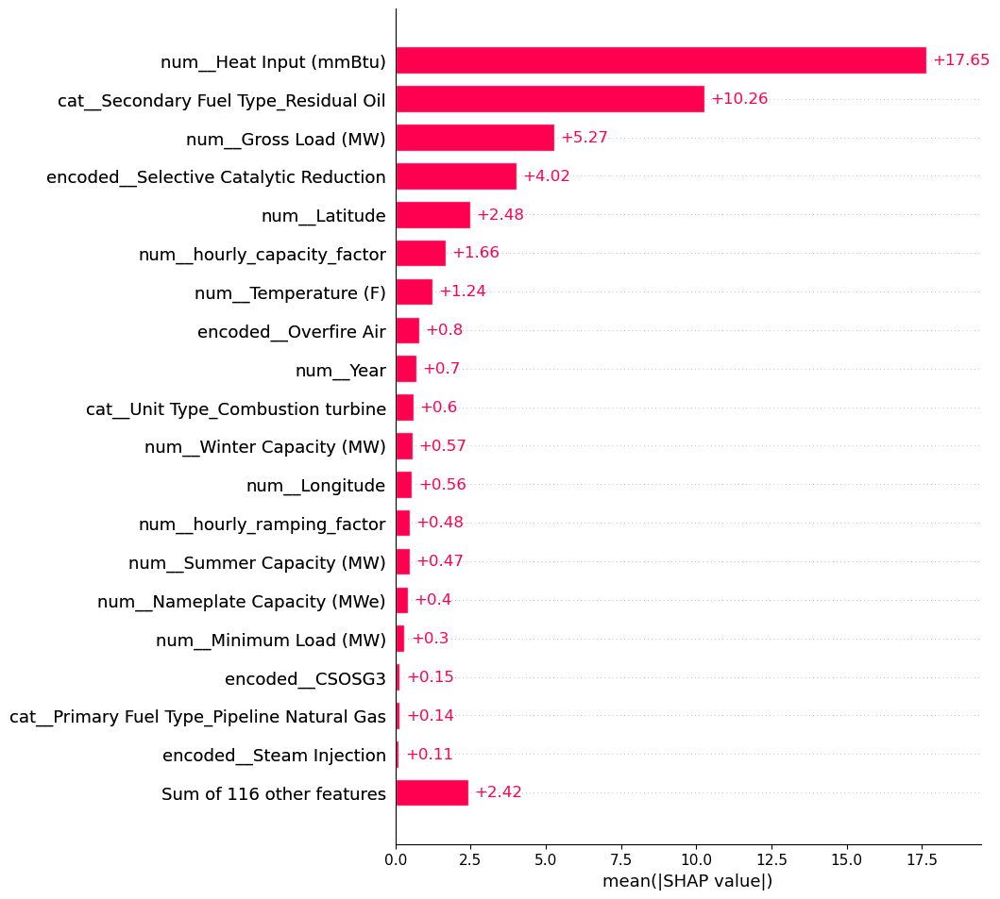

In [9]:
shap.plots.bar(shap_values, max_display=20)

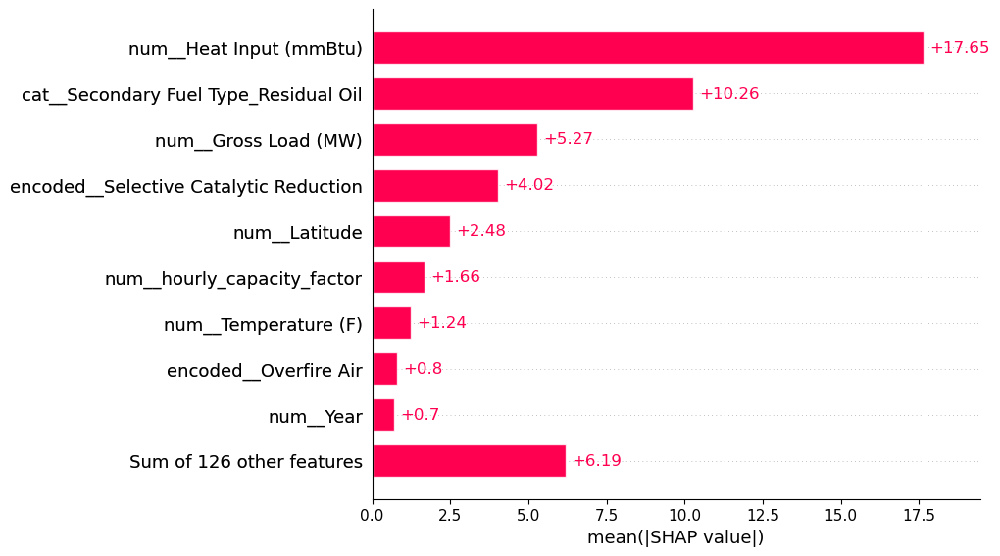

In [5]:
shap.plots.bar(shap_values, max_display=10)

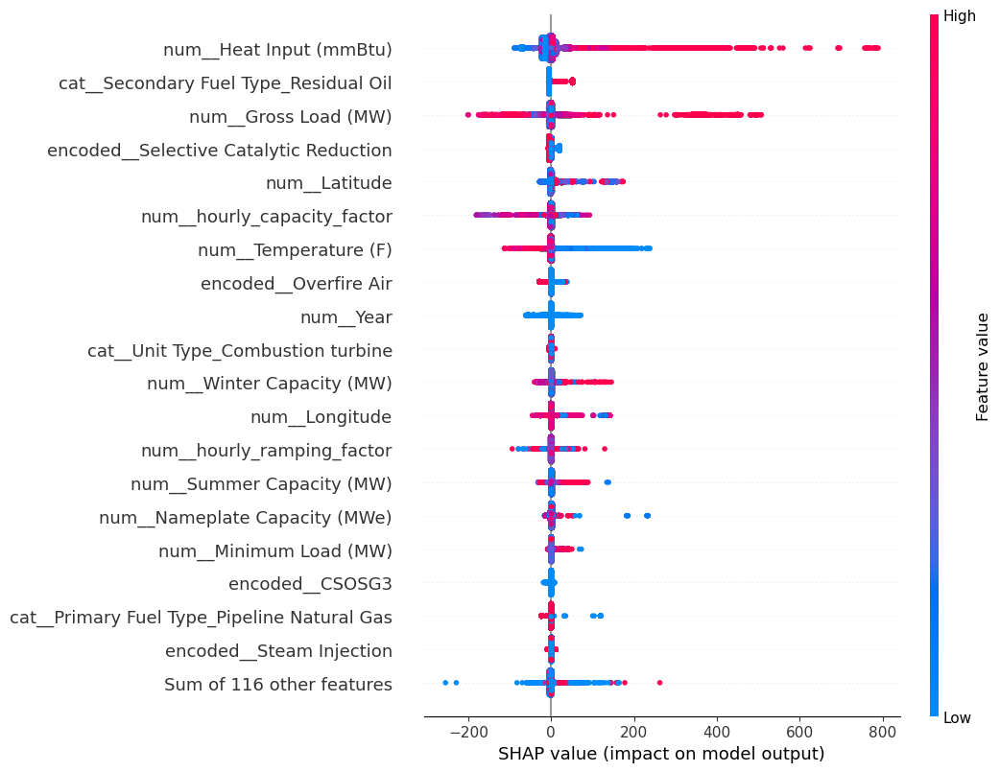

In [10]:
shap.plots.beeswarm(shap_values, max_display=20)

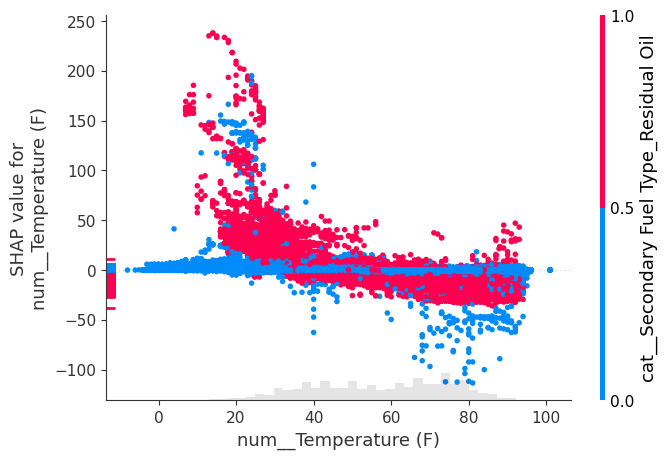

In [32]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

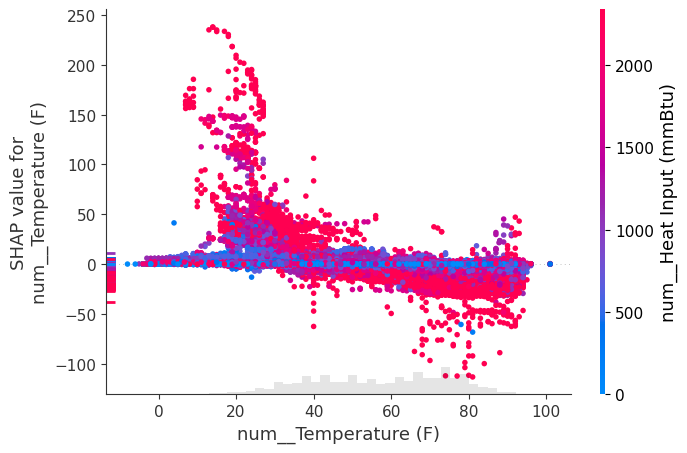

In [31]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


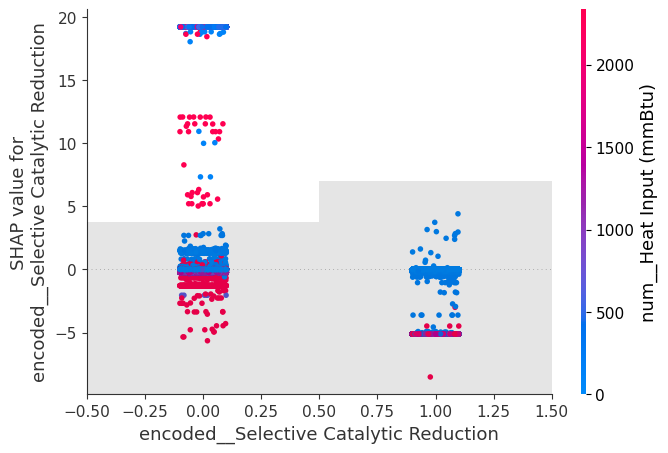

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

# effect of SCR is scattered wildy, no identifiable causal relationship 


<h4>XGB</h4>

<h5>SHAP Values</h5>

- global aggregated SHAP values with and without lags
- exploration of SHAP value scatter plots

In [ ]:
# with lags
explainer = shap.TreeExplainer(xgb_default_model_with_lags)
shap_values = explainer(X_test, approximate=False)
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured_with_temps.pkl")


In [7]:
shap_values = explainer(X_test, approximate=False)

In [8]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured_with_temps.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured_with_temps.pkl']

In [ ]:
joblib.load("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured_with_temps.pkl")

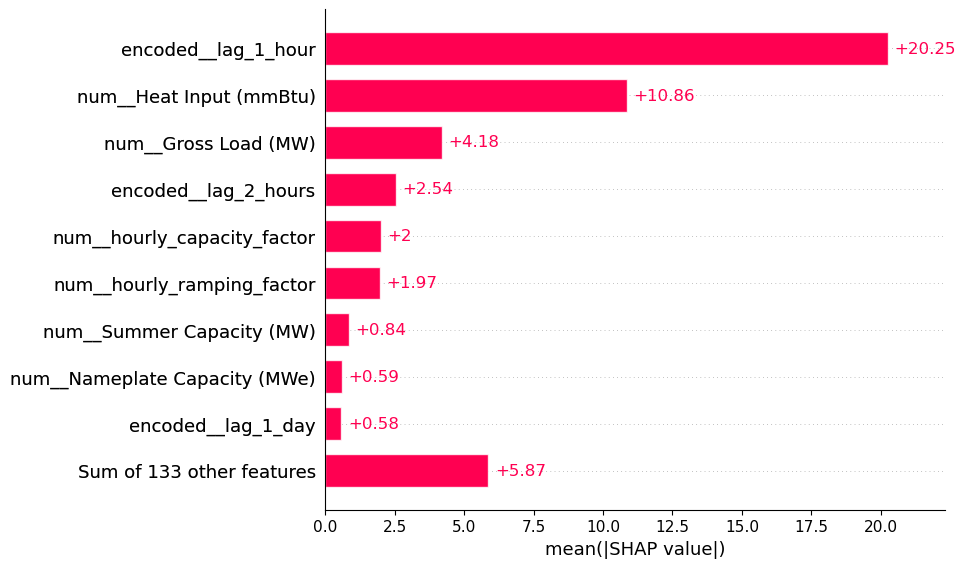

In [10]:
shap.plots.bar(shap_values, max_display=10) 

# overreliance on short term lags

In [ ]:
# without lags
explainer = shap.TreeExplainer(xgb_default_model_no_lags)
shap_values = explainer(X_test, approximate=False)
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

In [2]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

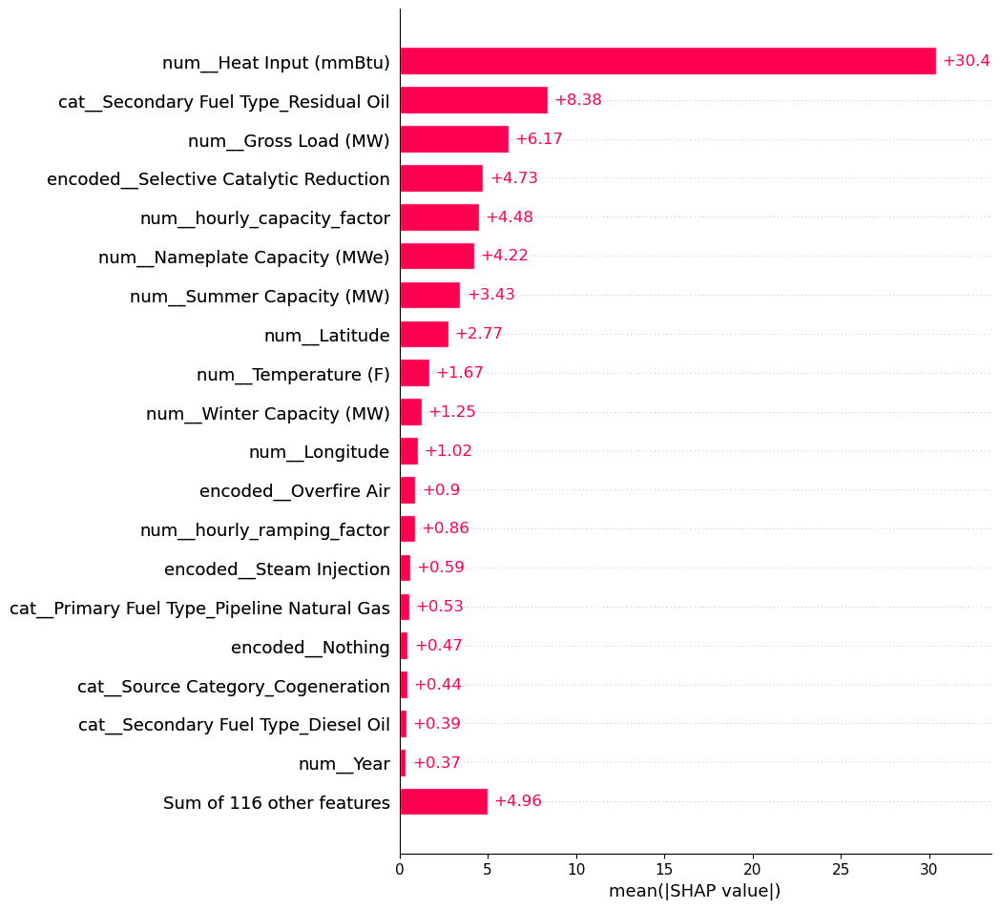

In [ ]:
shap.plots.bar(shap_values, max_display=20)

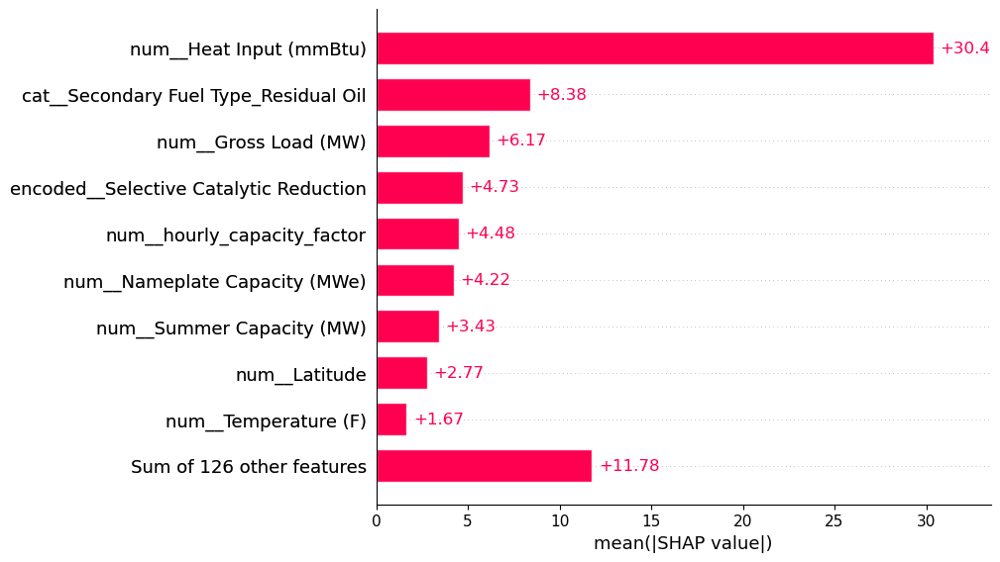

In [3]:
shap.plots.bar(shap_values, max_display=10)

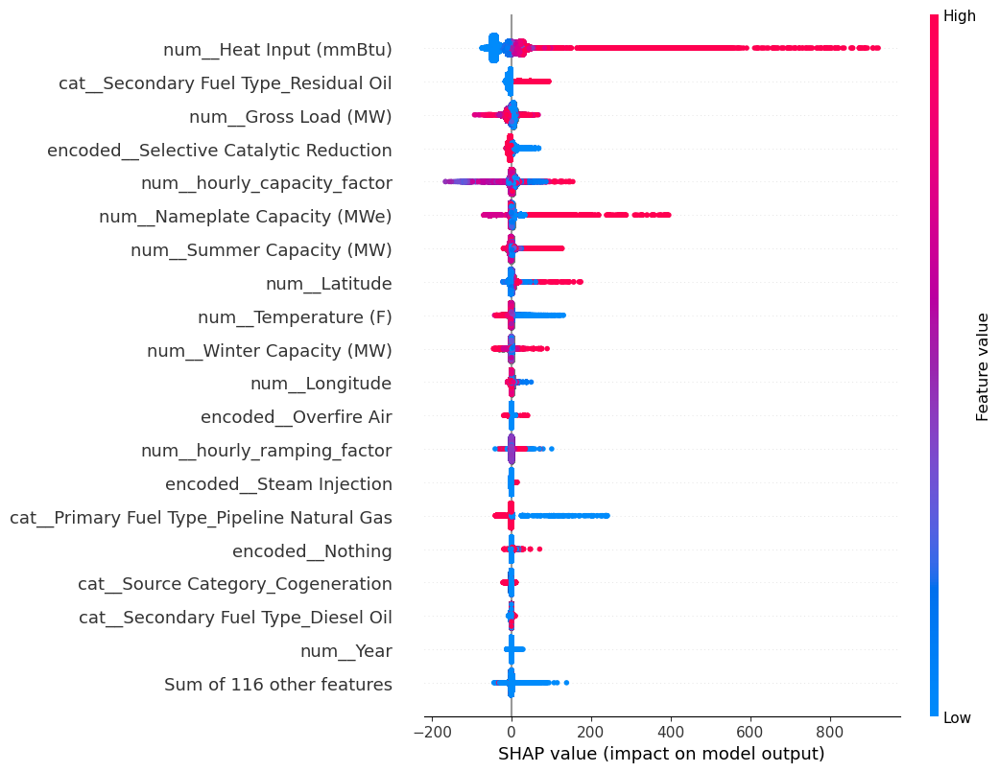

In [ ]:
shap.plots.beeswarm(shap_values, max_display=20)


In [11]:
# scatter plots

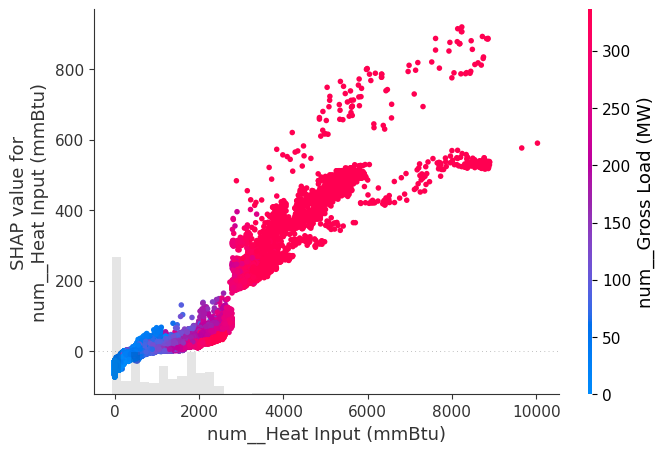

In [ ]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

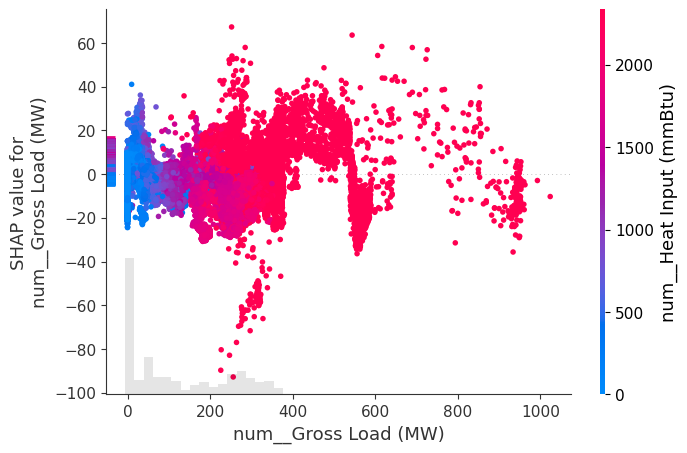

In [ ]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

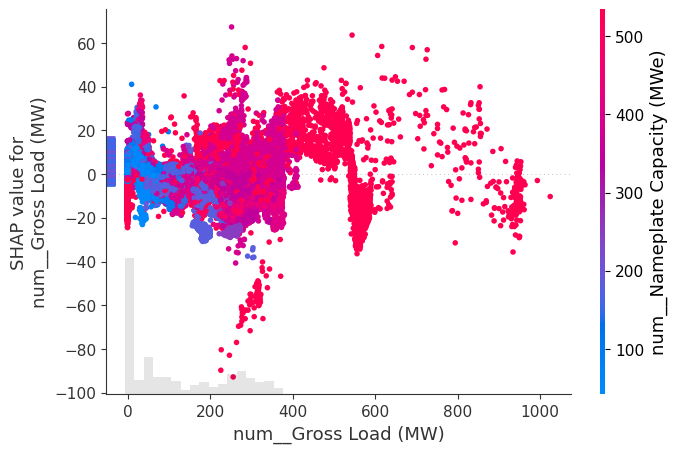

In [ ]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

c:\Users\marce\anaconda3\Lib\site-packages\shap\plots\_scatter.py:449: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


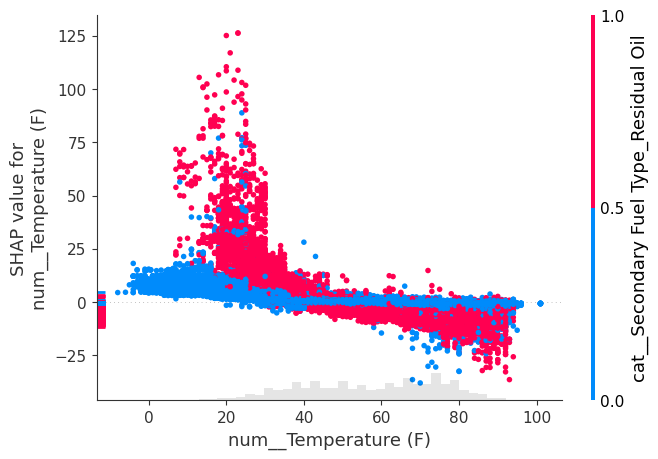

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

c:\Users\marce\anaconda3\Lib\site-packages\shap\plots\_scatter.py:449: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


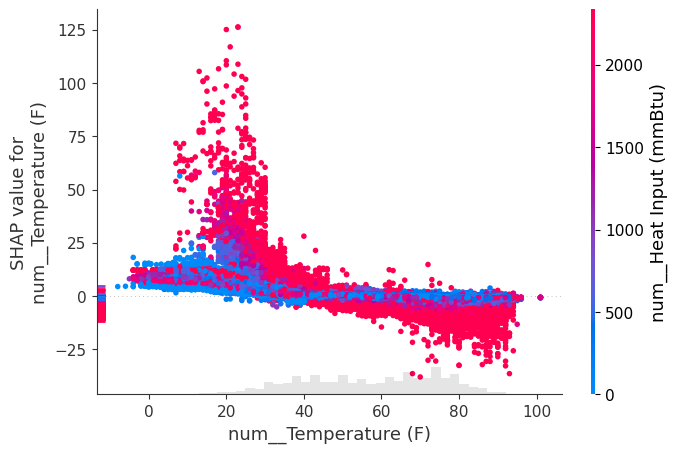

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

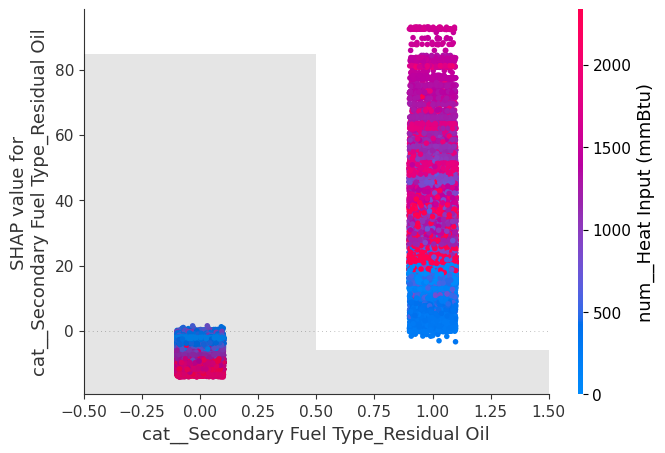

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Heat Input (mmBtu)"])

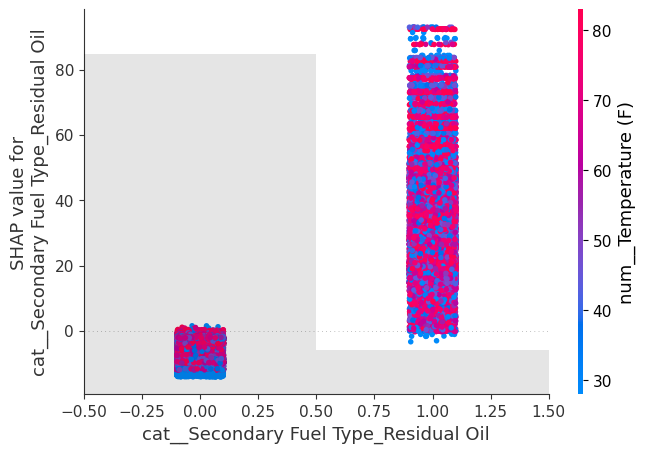

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Temperature (F)"])

# residual oil likely interacts with many other features different from temp making its shap value more complex
# (as opposed to temp where interactions with HI and Oil are clearly visible in a scatter plot, they are correlated with each other too making directionality more consistent)

<h5>Comparison of NOx Controls</h5>

- extract and compare NOx control behavior for different unit types + for primary fuel Pipeline Natural Gas

In [ ]:
# Filter using label-based indexing
comb_cycle_idx = X_test[X_test["cat__Unit Type_Combined cycle"] == 1].index
comb_turbine_idx = X_test[X_test["cat__Unit Type_Combustion turbine"] == 1].index
tangentially_fired_idx = X_test[X_test["cat__Unit Type_Tangentially-fired"] == 1].index

png_idx = X_test[X_test["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1].index
diesel_oil_idx = X_test[X_test["cat__Primary Fuel Type_Diesel Oil"] == 1].index

steam_injection_idx = X_test[X_test["encoded__Steam Injection"] == 1].index

# Convert to iloc-style positional indices (used to filter SHAP values later)
comb_cycle_iloc = X_test.index.get_indexer(comb_cycle_idx)
comb_turbine_iloc = X_test.index.get_indexer(comb_turbine_idx)
tangentially_fired_iloc = X_test.index.get_indexer(tangentially_fired_idx)

png_iloc = X_test.index.get_indexer(png_idx)

steam_injection_iloc = X_test.index.get_indexer(steam_injection_idx)

In [ ]:
# compare how many of the PNG rows are from different unit types
print("Rows of Pipeline Natural Gas in X_test:", png_iloc.shape[0])
print("PNG and Combined Turbine: ", np.intersect1d(comb_turbine_iloc, png_iloc).shape[0] / png_iloc.shape[0])
print("PNG and Combined Cycle: ", np.intersect1d(comb_cycle_iloc, png_iloc).shape[0] / png_iloc.shape[0])
print("PNG and Tangentially Fired: ", np.intersect1d(tangentially_fired_iloc, png_iloc).shape[0] / png_iloc.shape[0])

Rows of Pipeline Natural Gas in X_test: 435131
PNG and Combined Turbine:  0.19720727780829223
PNG and Combined Cycle:  0.620040861257874
PNG and Tangentially Fired:  0.1381606918376305


In [ ]:
# create list of controls cols, formatted as in train-test split
adj_control_cols = []
for control in df_control_cols:
    control = "encoded__" + control
    adj_control_cols.append(control)

In [ ]:
# filter shap values for different unit and fuel type combinations
# to explore corresponding beeswarm plots of control techs

shap_values_comb_cyle = shap_values[comb_cycle_iloc]
shap_values_comb_turbine = shap_values[comb_turbine_iloc]
shap_values_tangentially_fired = shap_values[tangentially_fired_iloc]

shap_values_png = shap_values[png_iloc]

shap_values_png_comb_cycle = shap_values[np.intersect1d(comb_cycle_iloc, png_iloc)]
shap_values_png_comb_turbine = shap_values[np.intersect1d(comb_turbine_iloc, png_iloc)]
shap_values_png_tangentially_fired = shap_values[np.intersect1d(tangentially_fired_iloc, png_iloc)]

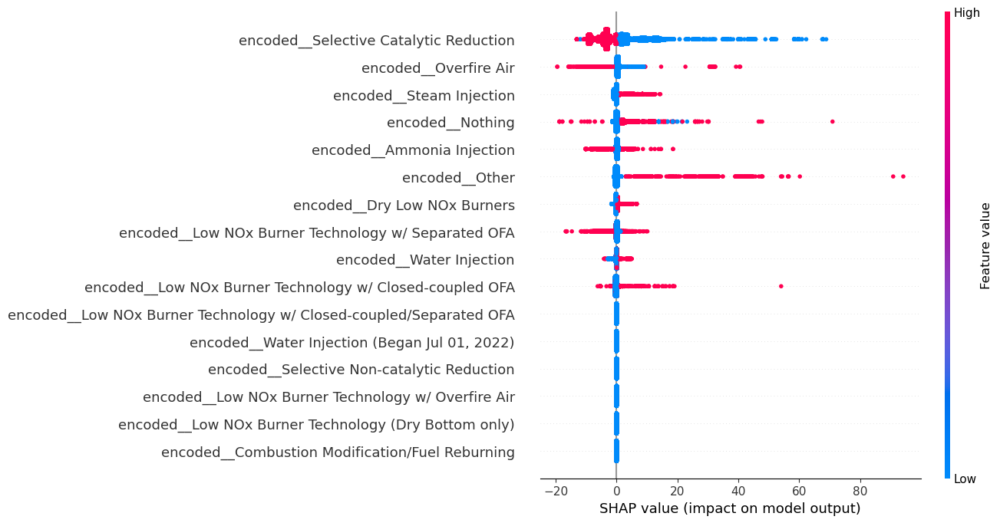

In [ ]:
# across all units and fuel types for comparison
shap.plots.beeswarm(shap_values[:, adj_control_cols], max_display=20)

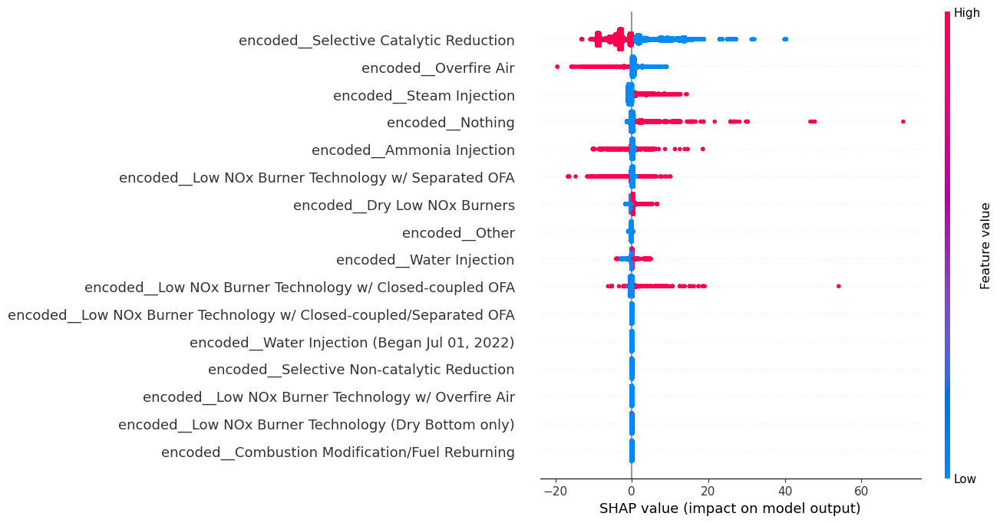

In [ ]:
# Pipeline Natural Gas

shap.plots.beeswarm(shap_values_png[:, adj_control_cols], max_display=20)
# pipeline natural gas units have lots of control techs
# e. g. steam injection appears to be consistently associated with higher emissions

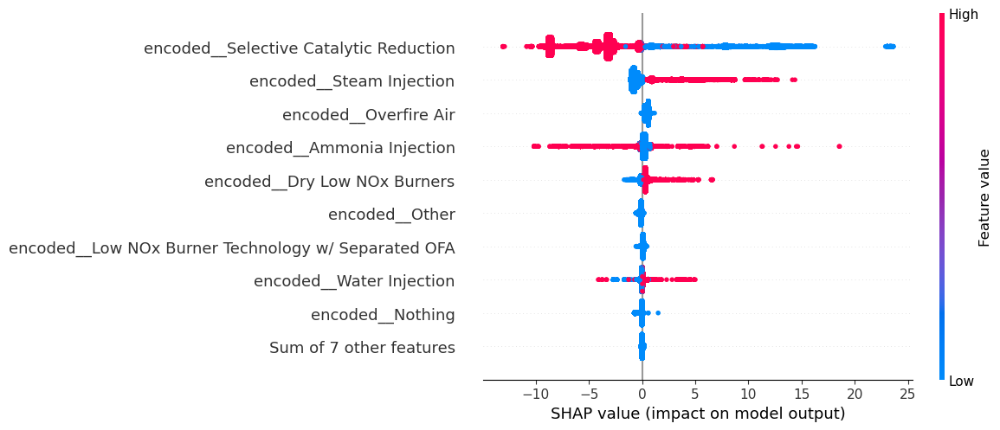

In [ ]:
# combined cycle units using pipeline natural gas as primary fuel
shap.plots.beeswarm(shap_values_png_comb_cycle[:, adj_control_cols], max_display=10)

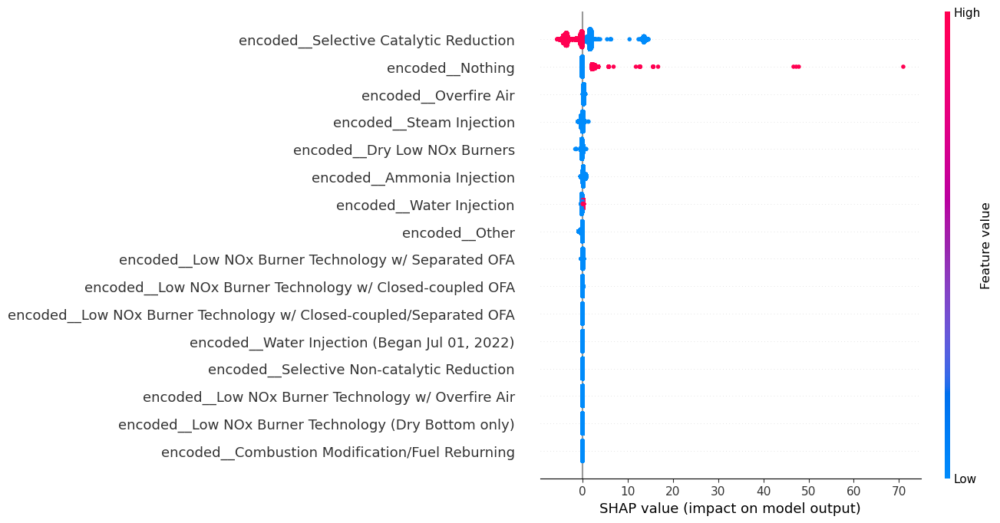

In [ ]:
# combined turbine units using pipeline natural gas as primary fuel
shap.plots.beeswarm(shap_values_png_comb_turbine[:, adj_control_cols], max_display=20)

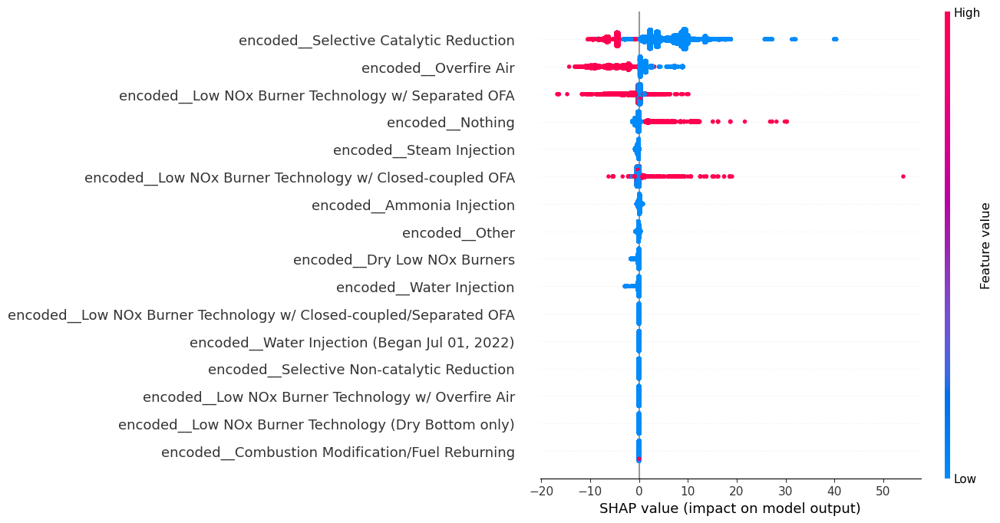

In [ ]:
# tangentially-fired cycle units using pipeline natural gas as primary fuel
shap.plots.beeswarm(shap_values_png_tangentially_fired[:, adj_control_cols], max_display=20)

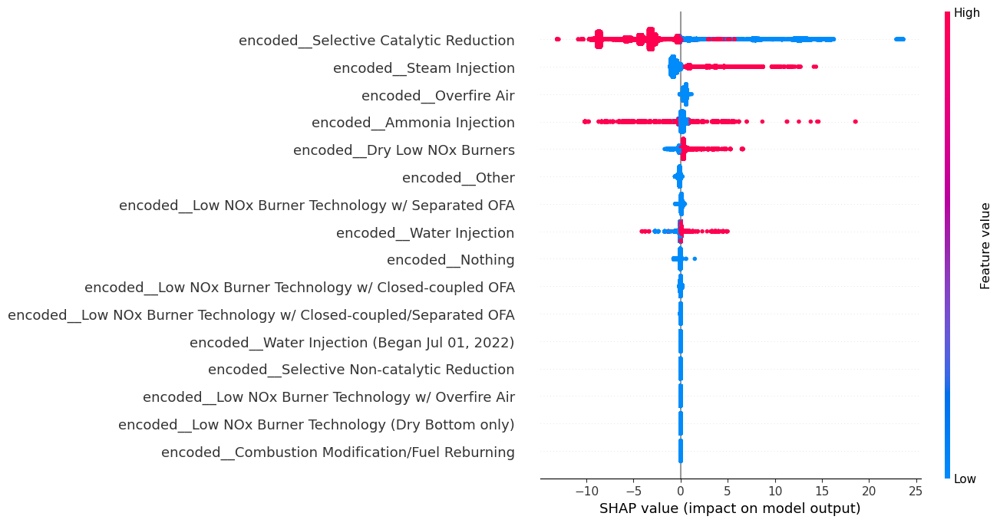

In [ ]:
# combined cycle units
shap.plots.beeswarm(shap_values_comb_cyle[:, adj_control_cols], max_display=20)

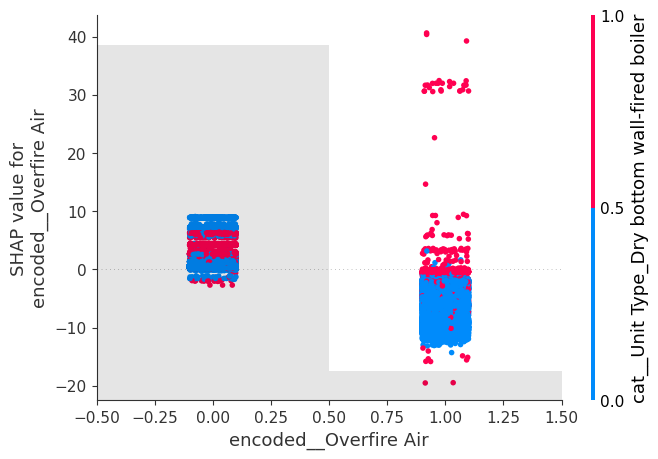

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"cat__Unit Type_Dry bottom wall-fired boiler"])


In [ ]:
campd_df[campd_df["Overfire Air"] == 1]["NOx Mass (lbs)"].describe()

count    207093.000000
mean         95.305443
std         121.981155
min           0.000000
25%          12.450000
50%          64.099998
75%         127.099998
max        2738.500000
Name: NOx Mass (lbs), dtype: float64

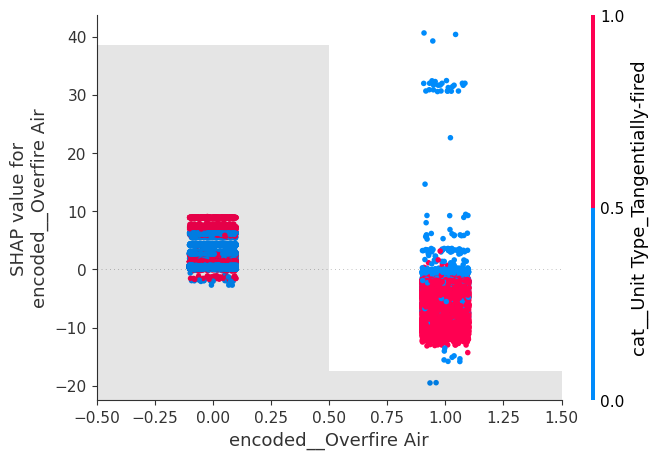

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"cat__Unit Type_Tangentially-fired"])


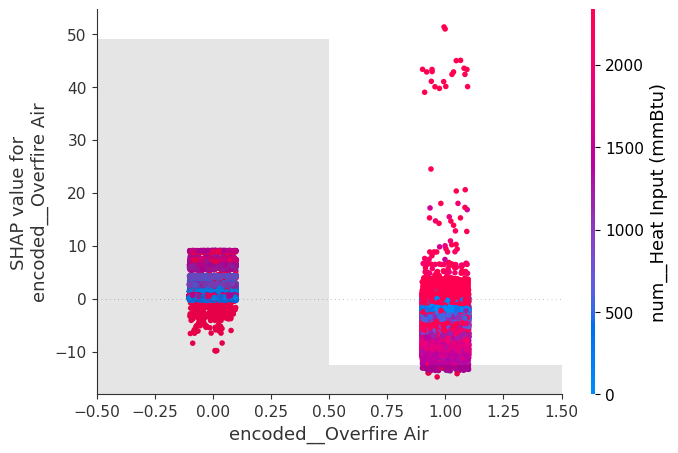

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"num__Heat Input (mmBtu)"])

# OFA shows the expected negative effect when Heat Input is low to moderate, but a positive effect when Heat Input is high

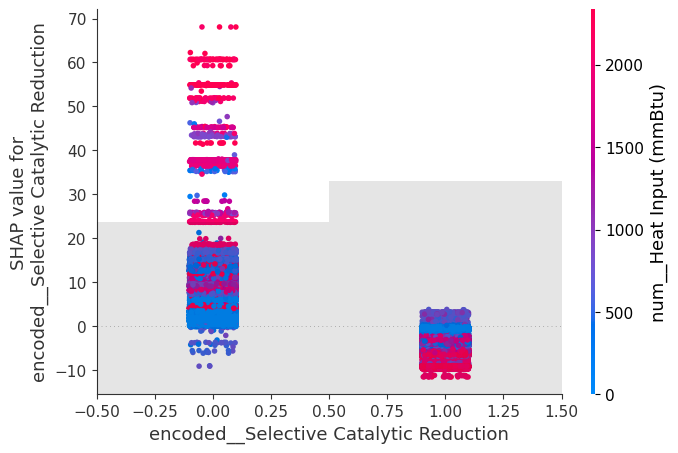

In [ ]:
# interaction between SCR and Heat Input is straightforward
# If SCR is present and heat input is high, then effect towards emissions is highly negative (negative SHAP value)
# If SCR is not present and heat input is high, then effect towards emissions is extremely large 

# note only units with relatively low heat input seem to have SCR
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>SHAP Interaction Values</h5>

- calculate 2nd-order SHAP interaction values for the model without lags using a 100,000 row sample to limit computational strain
- to validate, we aggregate these interaction values globally and compare with the SHAP values computed on the full X_test earlier
- compute and visualize global mean absolute interaction values
- explore dependence plots (scatter plots of interaction values)

In [ ]:
X_test_sample = X_test.sample(n=100000, random_state=42)

interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 61 mins

joblib.dump(interaction_values_shap, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

In [12]:
interaction_values_shap = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

In [ ]:
# first we explore how consistent the SI are with SV

In [ ]:
interaction_values_shap.shape

# interaction_values_shap[i][j][j] gives the main effect of feature j for sample i
# interaction_values_shap[i][j][k] gives the interaction effect of feature j and k for sample i (this is symmetric)

(100000, 135, 135)

In [ ]:
shap_values.feature_names[97]

'num__Heat Input (mmBtu)'

In [ ]:
# compare Heat Input shap value computed from interaction values for loc 306816
# and actual shap value for iloc 334080 (which is loc 306816)

print(interaction_values_shap[0][97].sum())
print(shap_values[334080][97].values)

-42.899097
-42.899097


In [ ]:
# now compare global absolute mean shap values for Heat Input 

print(np.abs(interaction_values_shap[:, 97, :].sum(axis=1)).mean()) # here we first manually compute shap values by iterating over all samples, looking at the interaction array for feature 97 (HI) and sum them to compute the shap value. Then we take the mean absolute val (do axis=1 to sum over each sample (each "row"))
print(np.abs(shap_values.values[:, 97]).mean())

30.454552
30.403566


In [ ]:
f = 97
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [ ]:
# compute total difference in global shap values between the two calculations

# create empty arrays
global_shap_vals_interact = np.zeros(interaction_values_shap.shape[1])
global_shap_vals_original = np.zeros(interaction_values_shap.shape[1])


for f in range(interaction_values_shap.shape[1]):
    # Sum interaction values for feature f across all interactions
    # then take absolute value and average over samples
    
    global_shap_vals_interact[f] = np.abs(interaction_values_shap[:, f, :].sum(axis=1)).mean()

    # Mean absolute shap value for feature f from original shap values
    global_shap_vals_original[f] = np.abs(shap_values.values[:, f]).mean()

Mean absolute difference: 0.001388
Max absolute difference: 0.050985
Min absolute difference: 0.000000


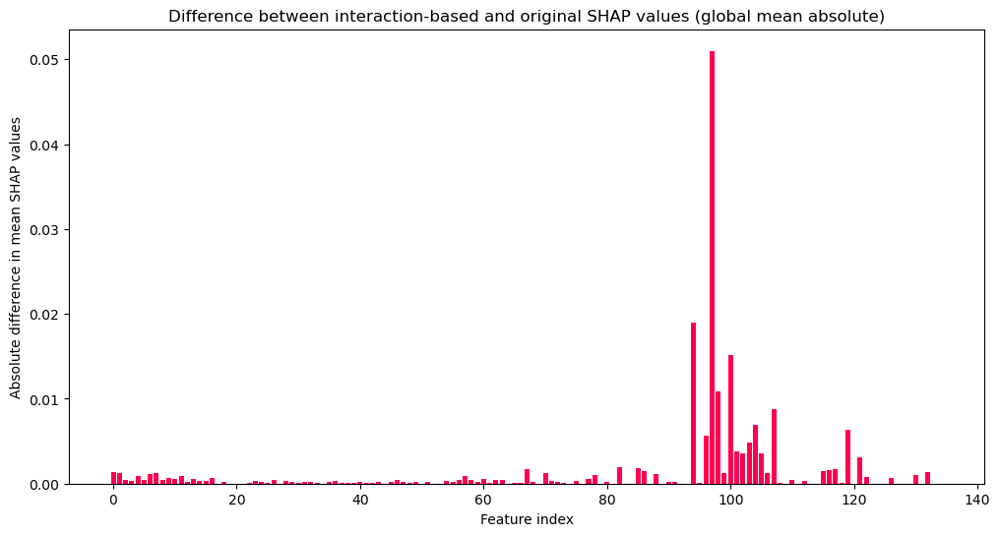

In [ ]:
# Compute the absolute differences between the two sets
differences = np.abs(global_shap_vals_interact - global_shap_vals_original)

# Summary stats
print(f"Mean absolute difference: {differences.mean():.6f}")
print(f"Max absolute difference: {differences.max():.6f}")
print(f"Min absolute difference: {differences.min():.6f}")

plt.figure(figsize=(12, 6))
plt.bar(range(len(differences)), differences, color='#FF0051')
plt.xlabel('Feature index')
plt.ylabel('Absolute difference in mean SHAP values')
plt.title('Difference between interaction-based and original SHAP values (global mean absolute)')
plt.show()

# very small differences, maximum is 0.05

In [21]:
flat_mean_abs

array([0.12673043, 0.00018507, 0.0009154 , ..., 0.        , 0.        ,
       0.        ], dtype=float32)

In [ ]:
# compute and visualize global mean absolute interaction values (pairwise and main effects)

In [ ]:
feature_names = shap_values.feature_names

n_samples, n_features, _ = interaction_values_shap.shape

# Mean interaction values for each feature pair (averaged over samples)
abs_mean_interactions = np.abs(interaction_values_shap).mean(axis=0)

# Flatten to 1D arrays for sorting (before it was shape (n_features, n_features))
flat_mean_abs = abs_mean_interactions.flatten()
# it becomes a 1D array of shape (n_features^2)

# Indices to map back to (feature1, feature2)
idxs = np.array([(i, j) for i in range(n_features) for j in range(n_features)])
# creates an array of tuples (i, j) for each feature pair (each index) with length n_features^2
# we use it to map feature names back later

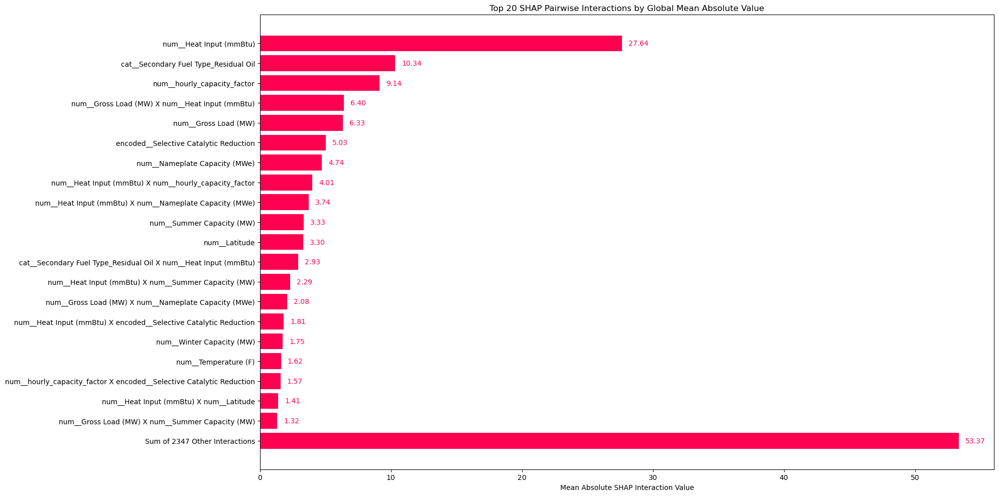

In [ ]:
# Indices to map back to (feature1, feature2), filtering symmetric duplicates
idxs = np.array([(i, j) for i in range(n_features) for j in range(i, n_features)])
# Now idxs only contains pairs where i <= j to avoid duplicates

# Updated flat_mean_abs and flat_mean_signed to account for symmetry reduction
flat_mean_abs = abs_mean_interactions[np.triu_indices(n_features)].flatten()
# Using np.triu_indices ensures only upper-triangular values are considered (i <= j)

# Filter out zero values by masking them before sorting
nonzero_mask = flat_mean_abs > 0
nonzero_indices = np.where(nonzero_mask)[0]
nonzero_values = flat_mean_abs[nonzero_mask]

# Get top 20 indices (in descending order) from non-zero interactions only
top20_abs_idx_nonzero = nonzero_indices[np.argsort(nonzero_values)[-20:][::-1]]
top20_abs_set = set(top20_abs_idx_nonzero)

# Values and labels for top 20 non-zero interactions
top20_abs = [((feature_names[i], feature_names[j]), flat_mean_abs[idx]) 
             for idx, (i, j) in zip(top20_abs_idx_nonzero, idxs[top20_abs_idx_nonzero])]
labels_abs = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_abs]
raw_values_abs = [v for _, v in top20_abs]

# Sum of others excluding top 20 and zero interactions
all_nonzero_indices = set(nonzero_indices)
other_abs_idx = list(all_nonzero_indices - top20_abs_set)
sum_other_abs = flat_mean_abs[other_abs_idx].sum()

# Append summary
labels_abs.append(f"Sum of {len(other_abs_idx)} Other Interactions")
raw_values_abs.append(sum_other_abs)

# All absolute values, one color
bar_colors_abs = ['#FF0051'] * len(labels_abs)

# Plot Absolute Interactions
plt.figure(figsize=(20, 10))
bars_abs = plt.barh(range(len(labels_abs)), raw_values_abs, color=bar_colors_abs)
plt.yticks(range(len(labels_abs)), labels_abs)
plt.xlabel("Mean Absolute SHAP Interaction Value")
plt.title("Top 20 SHAP Pairwise Interactions by Global Mean Absolute Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_abs, raw_values_abs):
    plt.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

In [ ]:
# explore dependence plots (scatter plots of interaction values)

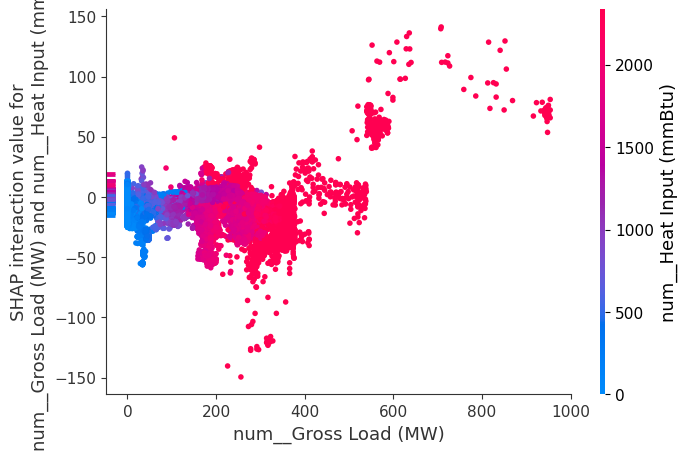

In [ ]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Heat Input (mmBtu)"), interaction_values_shap, X_test_sample, show=True)

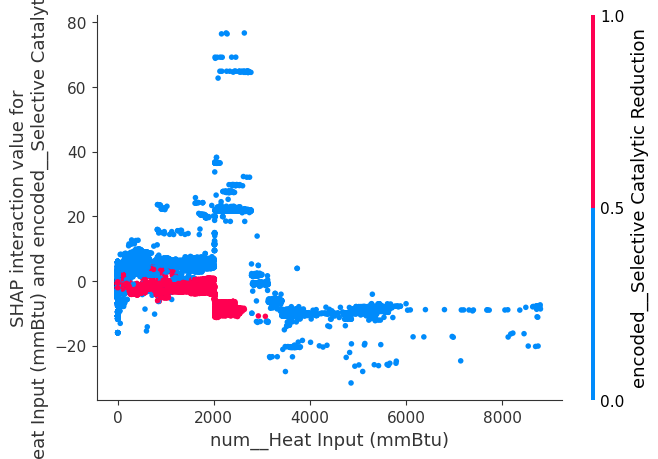

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Selective Catalytic Reduction"), interaction_values_shap, X_test_sample, show=True)

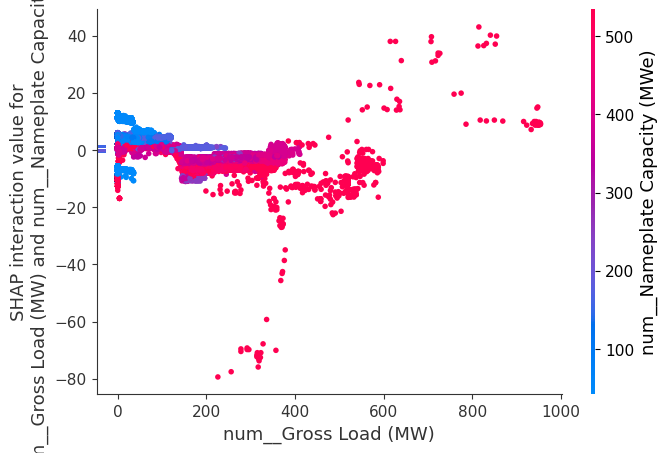

In [ ]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Nameplate Capacity (MWe)"), interaction_values_shap, X_test_sample, show=True)

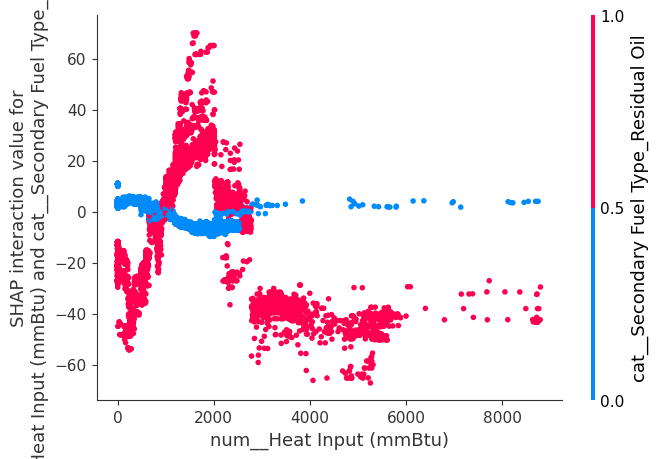

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

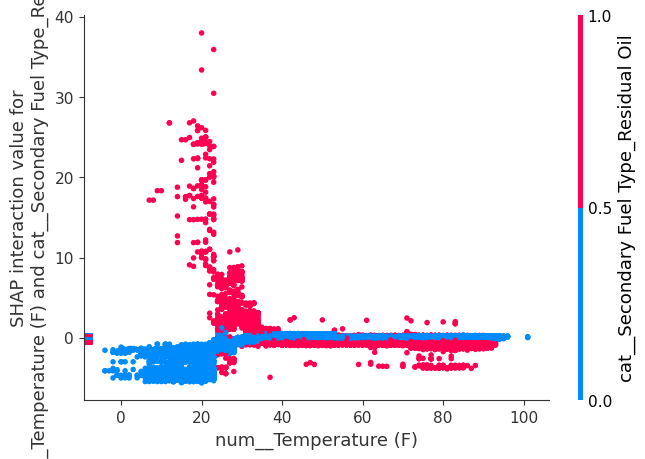

In [ ]:
shap.dependence_plot(("num__Temperature (F)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

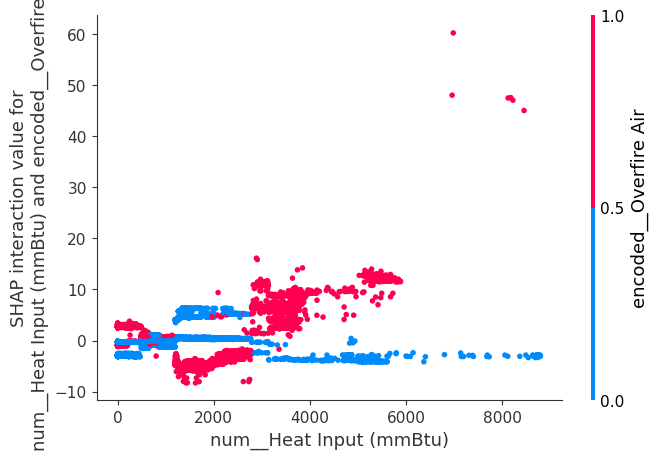

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Overfire Air"), interaction_values_shap, X_test_sample)


<h3>LIME</h3>

- explore some local LIME explanations
- compute global mean absolute LIME values

In [24]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

# Initialize the LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns.tolist(),
    mode='regression',
    discretize_continuous=False # need to do this since there are features in X_train and X_test with an std of 0 (consistent value)
)


In [ ]:
row = X_test.iloc[48384]

print(row[row.isna()])

# Fill nans in the row with median values (LIME cant handle nans)
row_filled = row.fillna(0)

lime_sample = row_filled.values

exp = lime_explainer.explain_instance(
    data_row=lime_sample,
    predict_fn=regressor.predict
)

exp.show_in_notebook(show_table=True)

num__Summer Capacity (MW)   NaN
num__Winter Capacity (MW)   NaN
num__Minimum Load (MW)      NaN
Name: 1720231, dtype: float64


In [ ]:
exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[482881].values,
    predict_fn=regressor.predict
)

exp.show_in_notebook(show_table=True)

In [ ]:
# aggregate LIME coefficients

feature_weights = defaultdict(list) # use to automatically add a new key with empty list if key does not exist yet

X_test_sample = X_test.sample(frac=0.1, random_state=42)
print(len(X_test_sample))

for i in range(len(X_test_sample)):
    row = X_test_sample.iloc[i]

    medians = X_test_sample.median()
    # Fill any nans in the row with median values
    row_filled = row.fillna(medians)

    exp = lime_explainer.explain_instance(
        data_row=row_filled.values,
        predict_fn=regressor.predict
    )
    for feature, weight in exp.as_list():
        feature_weights[feature].append(abs(weight))

global_importance = pd.DataFrame([
    (feat, np.mean(weights)) for feat, weights in feature_weights.items()
], columns=['Feature', 'Avg_Abs_Weight'])

global_importance = global_importance.sort_values(by='Avg_Abs_Weight', ascending=False)


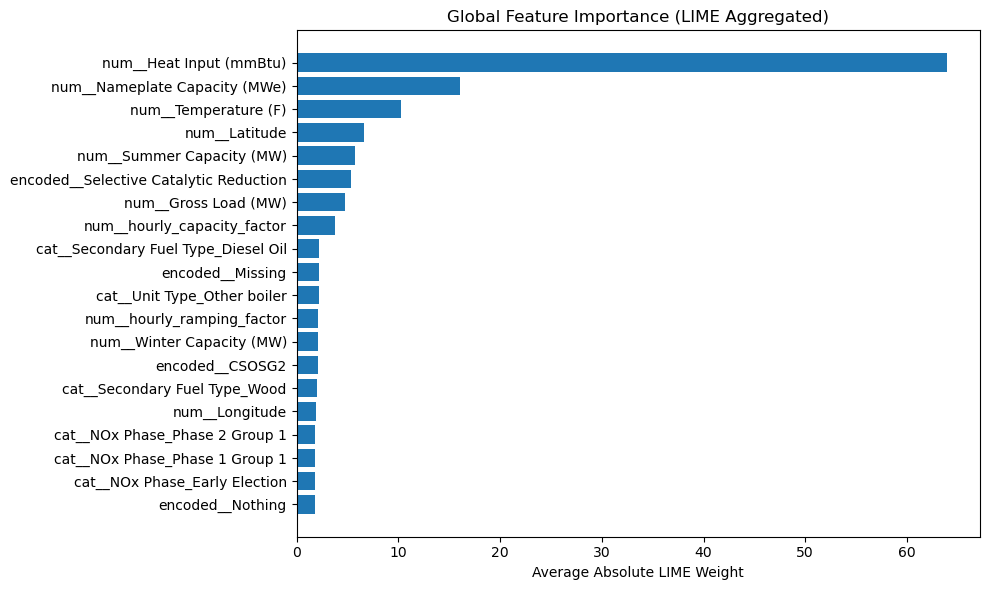

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(global_importance['Feature'].head(20), global_importance['Avg_Abs_Weight'].head(20))
plt.xlabel("Average Absolute LIME Weight")
plt.title("Global Feature Importance (LIME Aggregated)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# particularly interesting is that Secondary Fuel Type Residual Oil is not present here at all

<h3>Consistency Analysis of SHAP and LIME</h3>

- compare consistency of local explanations between SHAP and LIME by evaluating their rankings (overlap, mean absolute rank differnce, spearman correlation)
- look at a specific instance where they differ a lot

<h4>Calculation for a sample</h4>

In [18]:
shap_explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [ ]:
# Randomly select n indices
np.random.seed(42) # make sample reproducible
sample_indices = np.random.choice(X_test.index, size=10000)

medians = X_test.median()

spearman_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

overlap_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

mean_abs_rank_diff_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

normalized_mean_abs_rank_diff_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

# counters for at least conditions for k=3
agreement_counts = {
    "top 1": 0,
    "top 2": 0,
    "top 3": 0,
    "at_least_1": {3: 0},
    "at_least_2": {3: 0},
    "all_3": {3: 0}
}

# For fairness, we impute nan values with the median for both SHAP and LIME (LIME cannot deal with nans)
X_test_imputed = X_test.fillna(X_test.median())

for idx in tqdm(sample_indices): # progress bar
    try:
        sample_row = X_test_imputed.loc[[idx]]

        # SHAP
        shap_values = shap_explainer(sample_row)
        values = shap_values.values[0]
        features = shap_values.data[0]
        feature_names = shap_values.feature_names
        shap_df = pd.DataFrame({
            'Feature': feature_names,
            'Feature Value': features,
            'SHAP Value': values,
            'Absolute SHAP': abs(values)
        })

        shap_sorted = shap_df.sort_values(by='Absolute SHAP', ascending=False)

        # LIME
        exp = lime_explainer.explain_instance(
            data_row=sample_row.iloc[0].values,
            predict_fn=regressor.predict,
            num_features=20
        )
        lime_explanation = exp.as_list() # don't need to sort, already in order

        for k in [20, 10, 5, 3]:
            top_lime_features = [feature for feature, _ in lime_explanation[:k]]
            lime_ranks = {feature: rank for rank, feature in enumerate(top_lime_features)}
            # reuse sorted SHAP dataframe
            top_shap_features = shap_sorted.head(k)['Feature'].tolist()
            shap_ranks = {feature: rank for rank, feature in enumerate(top_shap_features)}

            common_features = list(set(top_shap_features) & set(top_lime_features))
            overlap = len(common_features) / k
            overlap_scores[k].append((idx, overlap)) # add idx to find specific rows later

            if len(common_features) >= 1:
                abs_rank_diffs = [np.abs(lime_ranks[feat] - shap_ranks[feat]) for feat in common_features]
                mean_abs_rank_diff_scores[k].append(np.mean(abs_rank_diffs))
                
                # also normalize by the maximum possible distance
                normalized_abs_rank_diffs = [(np.abs(lime_ranks[feat] - shap_ranks[feat])) / (k - 1) for feat in common_features]
                normalized_mean_abs_rank_diff_scores[k].append(np.mean(normalized_abs_rank_diffs))

            # Only calculate Spearman if there is overlap with at least two features
            if len(common_features) >= 2:
                shap_rank_list = [shap_ranks[feat] for feat in common_features]
                lime_rank_list = [lime_ranks[feat] for feat in common_features]
                correlation, _ = spearmanr(shap_rank_list, lime_rank_list)
                spearman_scores[k].append(correlation)

            # specific rank agreements in the top 3
            if k == 3:
                # exact rank matches
                if top_lime_features[0] == top_shap_features[0]:
                    agreement_counts["top 1"] += 1
                if top_lime_features[1] == top_shap_features[1]:
                    agreement_counts["top 2"] += 1
                if top_lime_features[2] == top_shap_features[2]:
                    agreement_counts["top 3"] += 1

                # at least x exact rank matches
                matches = sum(top_lime_features[i] == top_shap_features[i] for i in range(3))
                if matches >= 1:
                    agreement_counts["at_least_1"][3] += 1
                if matches >= 2:
                    agreement_counts["at_least_2"][3] += 1
                if matches == 3:
                    agreement_counts["all_3"][3] += 1

    except Exception as e:
        print(f"Error at index {idx}: {e}")
        continue


In [47]:
# reminder that we only calculate the spearman correlation for >= 2 overlapping features !
# mean abs rank difference is calculate for >= 1 overlapping features
for k in [20, 10, 5, 3]:
    current_spearman_scores = np.array(spearman_scores[k])
    current_overlap_scores = np.array(overlap_scores[k])
    current_mean_abs_rank_diff_scores = np.array(mean_abs_rank_diff_scores[k])
    current_normalized_mean_abs_rank_diff_scores = np.array(normalized_mean_abs_rank_diff_scores[k])

    print(f"Top {k} Features")
    print(f"Overlap Score: Mean = {np.mean(current_overlap_scores[:, 1]):.3f}, Std = {np.std(current_overlap_scores[:, 1]):.3f}, N = {len(current_overlap_scores)}")
    print(f"Mean Absolute Rank Diff Score: Mean = {np.mean(current_mean_abs_rank_diff_scores):.3f}, Std = {np.std(current_mean_abs_rank_diff_scores):.3f}, N = {len(current_mean_abs_rank_diff_scores)}")
    print(f"Normalized Mean Absolute Rank Diff Score: Mean = {np.mean(current_normalized_mean_abs_rank_diff_scores):.3f}, Std = {np.std(current_normalized_mean_abs_rank_diff_scores):.3f}, N = {len(current_normalized_mean_abs_rank_diff_scores)}")
    print(f"Spearman Correlation: Mean = {np.mean(current_spearman_scores):.3f}, Std = {np.std(current_spearman_scores):.3f}, N = {len(current_spearman_scores)}")
    print("")

Top 20 Features
Overlap Score: Mean = 0.605, Std = 0.079, N = 10000
Mean Absolute Rank Diff Score: Mean = 4.298, Std = 1.020, N = 10000
Normalized Mean Absolute Rank Diff Score: Mean = 0.226, Std = 0.054, N = 10000
Spearman Correlation: Mean = 0.452, Std = 0.231, N = 10000

Top 10 Features
Overlap Score: Mean = 0.640, Std = 0.098, N = 10000
Mean Absolute Rank Diff Score: Mean = 2.518, Std = 0.707, N = 10000
Normalized Mean Absolute Rank Diff Score: Mean = 0.280, Std = 0.079, N = 10000
Spearman Correlation: Mean = 0.268, Std = 0.326, N = 10000

Top 5 Features
Overlap Score: Mean = 0.426, Std = 0.147, N = 10000
Mean Absolute Rank Diff Score: Mean = 0.805, Std = 0.801, N = 9979
Normalized Mean Absolute Rank Diff Score: Mean = 0.201, Std = 0.200, N = 9979
Spearman Correlation: Mean = 0.695, Std = 0.630, N = 8145

Top 3 Features
Overlap Score: Mean = 0.366, Std = 0.167, N = 10000
Mean Absolute Rank Diff Score: Mean = 0.248, Std = 0.497, N = 9252
Normalized Mean Absolute Rank Diff Score: Mea

In [49]:
# agreement on most important features by specific rank
print(agreement_counts["top 1"] / 10000 * 100)
print(agreement_counts["top 2"] / 10000 * 100)
print(agreement_counts["top 3"] / 10000 * 100)

print("")

# agreement on at least x features in the top 3
print(agreement_counts["at_least_1"][3] / 10000 * 100)
print(agreement_counts["at_least_2"][3] / 10000 * 100)
print(agreement_counts["all_3"][3] / 10000 * 100)

71.69
8.04
7.5200000000000005

74.44
12.23
0.58


In [259]:
# visualizations

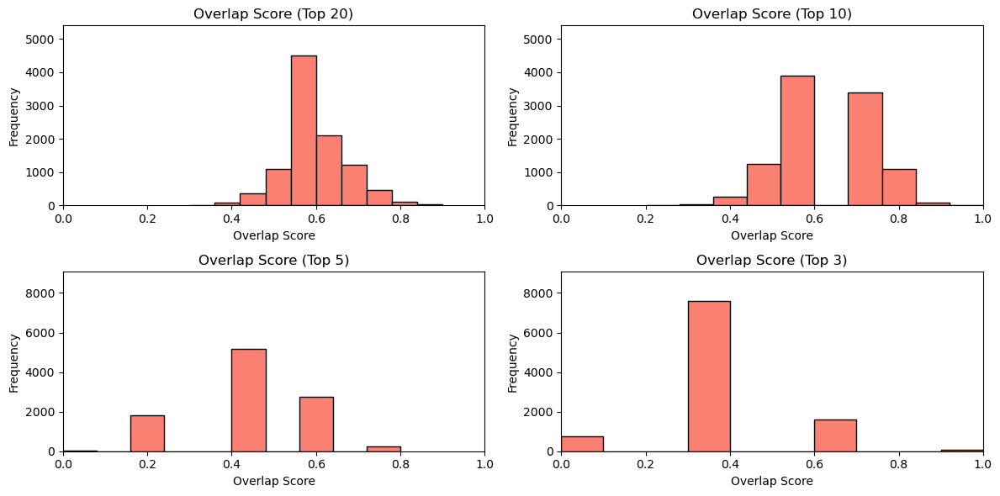

In [55]:

# Get all scores
scores_by_k = {k: [score[1] for score in overlap_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="salmon", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="salmon", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Overlap Score (Top {k})")
    plt.xlabel("Overlap Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

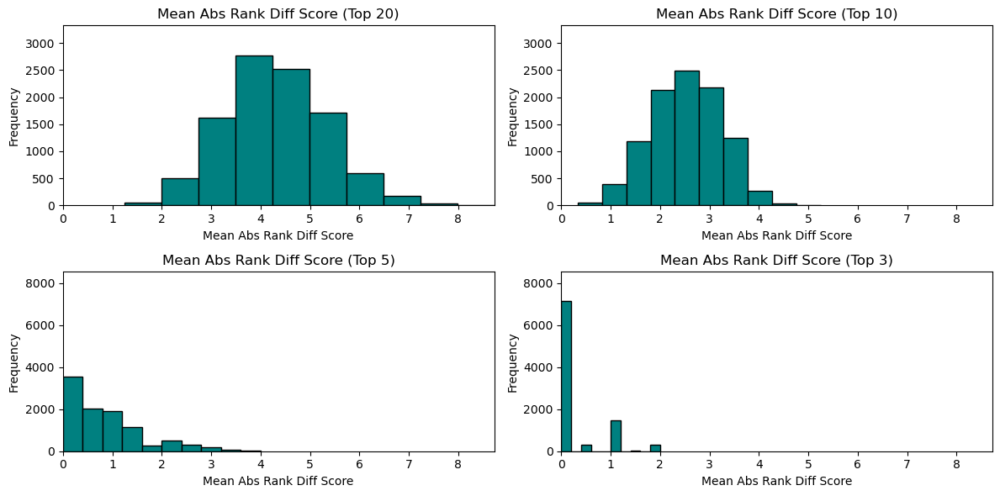

In [56]:

# Get all scores
scores_by_k = {k: [score for score in mean_abs_rank_diff_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="teal", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="teal", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Mean Abs Rank Diff Score (Top {k})")
    plt.xlabel("Mean Abs Rank Diff Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

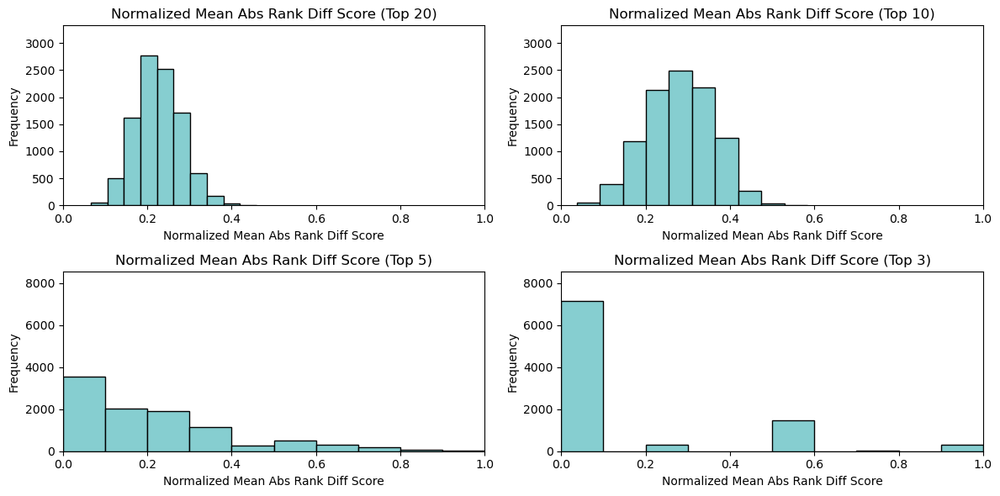

In [57]:

# Get all scores
scores_by_k = {k: [score for score in normalized_mean_abs_rank_diff_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="#86CED0", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="#86CED0", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Normalized Mean Abs Rank Diff Score (Top {k})")
    plt.xlabel("Normalized Mean Abs Rank Diff Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

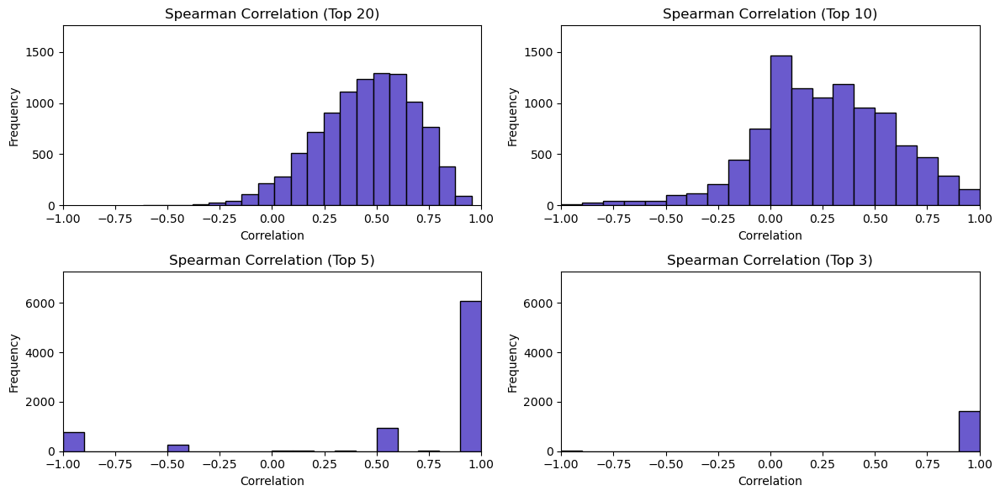

In [58]:
# Get all scores
scores_by_k = {k: [score for score in spearman_scores[k]] for k in [20, 10, 5, 3]}

# Row-wise ymax calculation
row1_ys = [np.histogram(scores_by_k[k], bins=20)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=20)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.hist(scores_by_k[k], bins=20, color="slateblue", edgecolor="black")
    plt.xlim(xmin, xmax)
    
    # Apply row-specific y-axis limits
    if i < 2:
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.ylim(0, ymax_row2*1.2)
    
    plt.title(f"Spearman Correlation (Top {k})")
    plt.xlabel("Correlation")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# spearman corr shows massive spikes at -1 and 1 for Top 5 and Top 3
# since most common feature sets at that level only consist of two features 
# which limits the correlation coefficient to -1 or 1

<h4>Specific Instance</h4>

In [ ]:
# look at a concrete instance with major differences

In [180]:
X_test_adjusted_sample = X_test.fillna(medians)

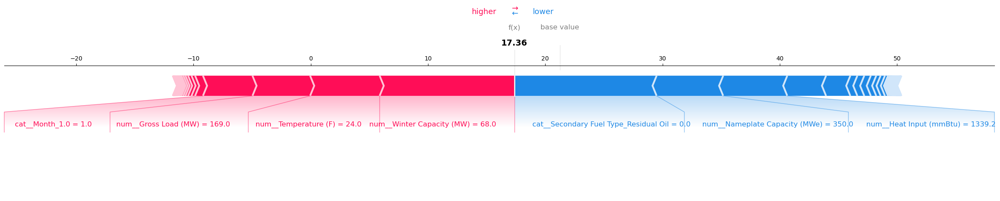

In [182]:
shap.plots.force(shap_explainer(X_test_adjusted_sample.loc[[2624710]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))


In [ ]:
shap_values = shap_explainer(X_test_adjusted_sample.loc[[2624710]])
values = shap_values.values[0] # loc 2624710 is iloc 0
features = shap_values.data[0]
feature_names = shap_values.feature_names
shap_df = pd.DataFrame({
            'Feature': feature_names,
            'Feature Value': features,
            'SHAP Value': values,
            'Absolute SHAP': abs(values)
        })

shap_df.sort_values(by="Absolute SHAP", ascending=False).head(20).reset_index(drop=True)

,Feature,Feature Value,SHAP Value,Absolute SHAP
0,cat__Secondary Fuel Type_Residual Oil,0.000000,-12.137015,12.137015
1,num__Winter Capacity (MW),68.000000,11.480815,11.480815
2,num__Temperature (F),24.000000,5.928749,5.928749
3,num__Nameplate Capacity (MWe),350.000000,-5.675828,5.675828
4,num__Heat Input (mmBtu),1339.200000,-5.465010,5.465010
5,num__Gross Load (MW),169.000000,4.916363,4.916363
6,cat__Month_1.0,1.000000,4.220865,4.220865
7,encoded__Selective Catalytic Reduction,1.000000,-3.305704,3.305704
8,num__hourly_capacity_factor,0.482857,-2.070254,2.070254
9,encoded__Overfire Air,0.000000,0.670697,0.670697


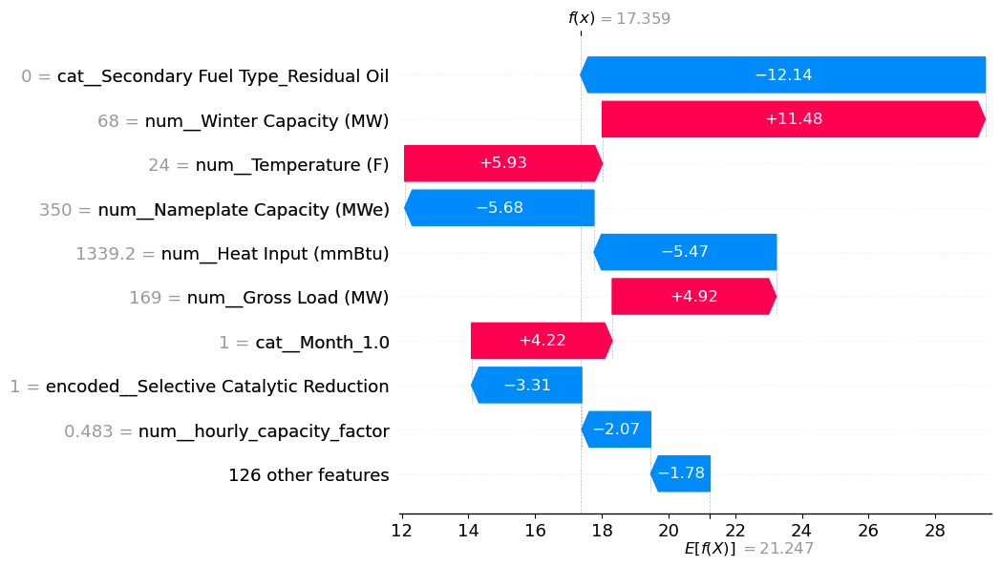

In [298]:
shap.plots.waterfall(shap_values[0], max_display=10)

In [275]:
# lime doesn't capture interactions so

# Explain the prediction
exp = lime_explainer.explain_instance(
    data_row=X_test_adjusted_sample.loc[2624710].values,
    predict_fn=regressor.predict,
    num_features=20
)

# Show explanation in notebook
exp.show_in_notebook(show_table=True)

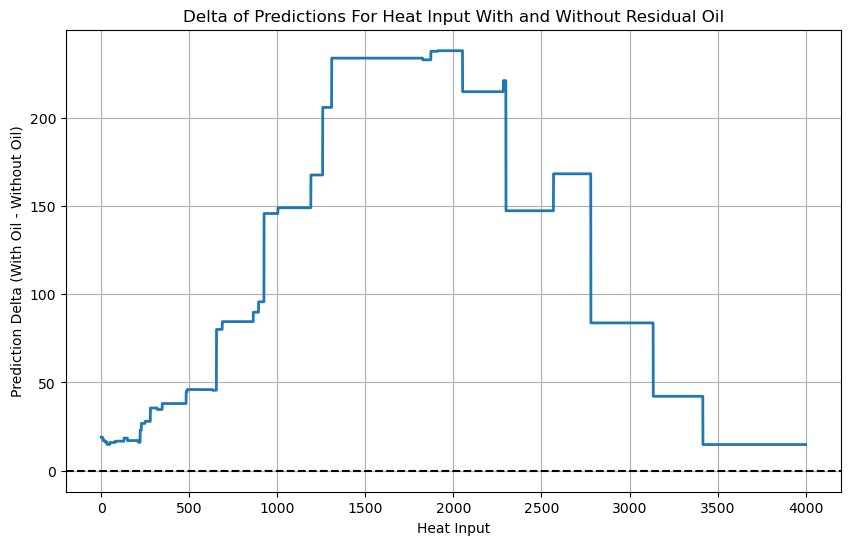

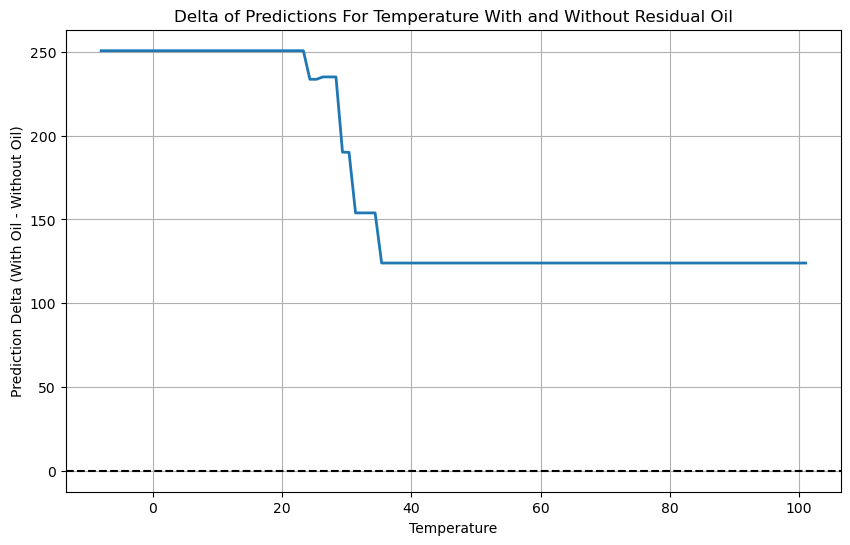

In [ ]:
# makeshift custom pdp

base_idx = 2624710 
base_sample = X_test_adjusted_sample.loc[base_idx].copy()

# Define range to test for heat input
hi_values = np.linspace(0, 4000, 4000) 

results = []

for hi in hi_values:
    # Set temperature value
    perturbed_sample = base_sample.copy()
    perturbed_sample['num__Heat Input (mmBtu)'] = hi

    # Set Residual Oil 0
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 0
    pred_no_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    # Set Residual Oil 1
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 1
    pred_with_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    results.append({
        'Heat Input': hi,
        'Prediction_No_Oil': pred_no_oil,
        'Prediction_With_Oil': pred_with_oil,
        'Delta': pred_with_oil - pred_no_oil
    })

results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 6))
plt.plot(results_df['Heat Input'], results_df['Delta'], linewidth=2)
plt.axhline(0, color='black', linestyle='--') # adds y=0 line to put magnitude into perspective
plt.title('Delta of Predictions For Heat Input With and Without Residual Oil')
plt.xlabel('Heat Input')
plt.ylabel('Prediction Delta (With Oil - Without Oil)')
plt.grid(True)
plt.show()

# with higher heat input, the impact of secondary fuel type residual oil rises
# up to a certain point at which its impact diminishes again


base_idx = 2624710 
base_sample = X_test_adjusted_sample.loc[base_idx].copy()

# Define temperature range to test
temperature_values = np.linspace(-8, 101, 109)  

results = []

for temp in temperature_values:
    # Set temperature value
    perturbed_sample = base_sample.copy()
    perturbed_sample['num__Temperature (F)'] = temp

    # Set Residual Oil 0
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 0
    pred_no_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    # Set Residual Oil 1
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 1
    pred_with_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    results.append({
        'Temperature': temp,
        'Prediction_No_Oil': pred_no_oil,
        'Prediction_With_Oil': pred_with_oil,
        'Delta': pred_with_oil - pred_no_oil
    })

results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 6))
plt.plot(results_df['Temperature'], results_df['Delta'], linewidth=2)
plt.axhline(0, color='black', linestyle='--')
plt.title('Delta of Predictions For Temperature With and Without Residual Oil')
plt.xlabel('Temperature')
plt.ylabel('Prediction Delta (With Oil - Without Oil)')
plt.grid(True)
plt.show()